*Mathematical Foundations of Robotics · Chapter 2 — Spatial Descriptions and Transformations*

# 2.5 Angle–Axis and Quaternions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/02-spatial-descriptions-and-transformations/2.5-angle-axis-and-quaternions.ipynb)

Three angles cannot describe every orientation without a singularity (Section 2.4). The remedy is to use *more*
numbers than three and to constrain them. This notebook develops the two redundant descriptions that robotics relies
on: the **angle–axis** pair — a unit axis and one angle, whose matrix form is Rodrigues' formula and whose
three-number version is the *rotation vector* or *exponential coordinates* — and the **unit quaternion**, four
numbers on a unit sphere that compose by a cheap product, never lose a degree of freedom, and interpolate smoothly
by SLERP. We derive the algebra from first principles, convert between all the representations, compare
interpolation by Euler angles with SLERP, watch rounding errors accumulate, and check everything against
the quaternions that MuJoCo computes for a real UR5e.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., §2.8 (equivalent angle–axis representation; Euler parameters) |
| **Parallel reading** | Lynch & Park §3.2.3 (exponential coordinates of rotation) and Appendix B (unit quaternions) · Siciliano et al. §2.5–2.6 · Spong et al. Ch. 2 (axis–angle) · Corke *RVC* Ch. 2 (quaternions) |
| **Lectures** | [Prof. G. C. Nandi, Lecture 10 — Rotation matrix when the body is rotated about a given axis](https://www.youtube.com/watch?v=eItbJ-WYzAE) · [Prof. G. C. Nandi, Lecture 13 — Orientation description using quaternion: why is it more useful?](https://www.youtube.com/watch?v=UxC8Ho5e6_Y) · [Prof. G. C. Nandi, Lecture 14 — Use of quaternion for rotation](https://www.youtube.com/watch?v=uGzl-TW68Pw) · [Modern Robotics 3.2.3 Exponential coordinates of rotation (part 1)](https://www.youtube.com/watch?v=v_KBHaG0mas) · [Modern Robotics 3.2.3 Exponential coordinates of rotation (part 2)](https://www.youtube.com/watch?v=WHn9xJl43nY) |
| **Prerequisites** | [2.4 Fixed Angles and Euler Angles](2.4-fixed-angles-and-euler-angles.ipynb) and the skew-symmetric matrix of [2.2](2.2-mappings-and-operators.ipynb) |
| **Study time** | about 3 hours, including the exercises |

## Learning objectives

After working through this notebook you should be able to:

1. state **Euler's rotation theorem** and derive **Rodrigues' formula** $R = I + \sin\theta\,[\hat k]_\times + (1-\cos\theta)[\hat k]_\times^2$ geometrically;
2. extract the axis and angle from a rotation matrix with a method that is accurate for every angle, including $\theta=0$ and $\theta=\pi$;
3. define **exponential coordinates** and prove $e^{[\hat\omega]\theta}$ equals Rodrigues' formula by power series; compute the **matrix logarithm** and check it with SciPy;
4. multiply quaternions from Hamilton's rule, and rotate a vector by $q\,\mathbf p\,q^{*}$; explain the **double cover** $q\leftrightarrow -q$ and the half-angle;
5. convert reliably among rotation matrices, angle–axis, quaternions and roll–pitch–yaw, and explain why the naive matrix-to-quaternion formula fails near $180^\circ$;
6. interpolate orientations with **SLERP**, demonstrate why interpolating Euler angles fails, and quantify the drift of products of matrices and quaternions in single precision;
7. read MuJoCo's **scalar-first** quaternions for every link of a real UR5e and verify them against `rgkit.transforms`.

## Contents

1. [Euler's rotation theorem and the angle-axis pair](#1.-Euler's-rotation-theorem-and-the-angle-axis-pair)
2. [Rodrigues' formula](#2.-Rodrigues'-formula)
3. [The inverse problem: from a matrix to an axis and an angle](#3.-The-inverse-problem:-from-a-matrix-to-an-axis-and-an-angle)
4. [Exponential coordinates and the matrix logarithm](#4.-Exponential-coordinates-and-the-matrix-logarithm)
5. [Quaternion algebra](#5.-Quaternion-algebra)
6. [Unit quaternions as rotations](#6.-Unit-quaternions-as-rotations)
7. [Conversions between representations](#7.-Conversions-between-representations)
8. [Interpolating orientations: SLERP versus Euler angles](#8.-Interpolating-orientations:-SLERP-versus-Euler-angles)
9. [Numerical drift and renormalisation](#9.-Numerical-drift-and-renormalisation)
10. [Quaternions in MuJoCo and a rotation vector for the UR5e](#10.-Quaternions-in-MuJoCo-and-a-rotation-vector-for-the-UR5e)
11. [Worked examples](#11.-Worked-examples)
12. [Summary, common mistakes and exercises](#12.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

import itertools
import sympy as sp
from scipy.linalg import expm, logm
from scipy.spatial.transform import Rotation as Rot
from rgkit.transforms import (rotx, roty, rotz, skew, unskew, is_rotation, rot_axis_angle, axis_angle_from_rot, rpy_to_rot,
                              rot_to_rpy, quat_mul, quat_conj, quat_from_axis_angle, quat_to_rot, rot_to_quat, quat_rotate, slerp,
                              orthonormalize)

def arc3d(ax, centre, u, v, t0, t1, r, **kw):
    """Circular arc of radius r in the plane spanned by the orthonormal vectors u, v."""
    t = np.linspace(t0, t1, 60)
    pts = np.asarray(centre)[:, None] + r * (np.outer(u, np.cos(t)) + np.outer(v, np.sin(t)))
    ax.plot(*pts, **kw)

## 1. Euler's rotation theorem and the angle-axis pair

Section 2.1 showed that every rotation matrix has an eigenvalue equal to $+1$. The consequence is a theorem of
great practical value.

> **Theorem (Euler's rotation theorem).** Every orientation of a rigid body that is reached from a reference
> orientation by any sequence of rotations about a fixed point can also be reached by a **single rotation** through
> some angle $\theta$ about some axis through that point.

*Proof.* For $R\in SO(3)$, $\det(R-I) = \det(R-RR^{\mathsf T}) = \det R\,\det(I-R^{\mathsf T}) = \det\big((I-R)^{\mathsf T}\big) =
\det(I-R) = (-1)^3\det(R-I)$, hence $\det(R-I)=0$: the matrix $R-I$ is singular, so $R\hat k=\hat k$ for some unit vector
$\hat k\neq 0$ — the axis. Rotating the frame about $\hat k$ leaves $\hat k$ fixed and turns the plane perpendicular to
it by some angle $\theta$, which is the angle of the rotation. $\blacksquare$

The pair $(\hat k,\theta)$ is the **equivalent angle–axis** representation of $R$. It has four numbers and one
constraint ($\lVert\hat k\rVert=1$), and three degrees of freedom: two for the direction of the axis on the unit
sphere and one for the angle. It is not unique: $(\hat k,\theta)$, $(-\hat k,-\theta)$ and $(\hat k,\theta+2\pi n)$
describe the same rotation, and when $\theta=0$ the axis is arbitrary. Restricting the angle to
$0\le\theta\le\pi$ removes most of the ambiguity; the case $\theta=\pi$ keeps the ambiguity $\hat k\leftrightarrow-\hat k$.

The three-number combination $\boldsymbol r=\theta\hat k$, the **rotation vector**, packs the pair into one vector
(Section 4). Throughout, rotations are positive by the right-hand rule: with the thumb along $\hat k$, the fingers
curl in the direction of increasing $\theta$.

## 2. Rodrigues' formula

Let the rotation be through $\theta$ about the unit vector $\hat k$ (through the origin), acting on a vector $\mathbf p$
as an *operator*. Resolve $\mathbf p$ along the axis and perpendicular to it:

$$
\mathbf p_\parallel = (\hat k\cdot\mathbf p)\,\hat k,\qquad \mathbf p_\perp = \mathbf p-\mathbf p_\parallel .
$$

The rotation leaves $\mathbf p_\parallel$ unchanged. The perpendicular part turns by $\theta$ in the plane
perpendicular to $\hat k$. That plane is spanned by $\mathbf p_\perp$ and by $\hat k\times\mathbf p$ — which equals
$\hat k\times\mathbf p_\perp$, has the same length as $\mathbf p_\perp$, and is $\mathbf p_\perp$ turned by $90^\circ$ about $\hat k$. Therefore

$$
\mathbf p_\perp' = \cos\theta\,\mathbf p_\perp + \sin\theta\,(\hat k\times\mathbf p).
$$

Adding the unchanged parallel part and using $\mathbf p_\perp = \mathbf p-(\hat k\cdot\mathbf p)\hat k$,

$$
\mathbf p' = \cos\theta\,\mathbf p + (1-\cos\theta)(\hat k\cdot\mathbf p)\,\hat k + \sin\theta\,(\hat k\times\mathbf p).
$$

Now write the dot and cross products with the skew-symmetric matrix of Section 2.2, $\hat k\times\mathbf p = [\hat k]_\times\mathbf p$,
and use the identity $[\hat k]_\times^2 = \hat k\hat k^{\mathsf T} - I$ (a consequence of the "bac-cab" rule
$\hat k\times(\hat k\times\mathbf p)=\hat k(\hat k\cdot\mathbf p)-\mathbf p$):

> **Rodrigues' rotation formula (Craig eq. 2.80).**
> $$ R_{\hat k}(\theta) = I + \sin\theta\,[\hat k]_\times + (1-\cos\theta)\,[\hat k]_\times^2 = \cos\theta\,I+(1-\cos\theta)\,\hat k\hat k^{\mathsf T}+\sin\theta\,[\hat k]_\times . $$

Writing $v\theta = 1-\cos\theta$ (the "versine"), the entries are $r_{11}=k_x^2v\theta+c\theta$,
$r_{12}=k_xk_yv\theta-k_zs\theta$, $r_{13}=k_xk_zv\theta+k_ys\theta$, and so on. A useful sanity check is
$\hat k=\hat Z$, which must reproduce $R_Z(\theta)$. The figure shows the geometry, and the cell evaluates the formula,
symbolically and numerically.

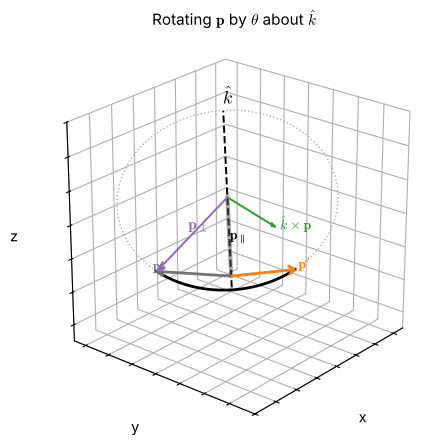

<IPython.core.display.Math object>

symbolic entries agree with rgkit.rot_axis_angle: True
k = Z reproduces R_Z(theta): True
operator view: p' = [0.361  0.8289 0.371 ]   |p'| = |p|: True   k.p' = k.p: True


In [2]:
k = np.array([0.35, 0.25, 0.9]); k /= np.linalg.norm(k)
theta = deg(75)
p = np.array([0.9, 0.15, 0.35])
p_par = (k @ p) * k; p_perp = p - p_par; kxp = np.cross(k, p)
p_new = rot_axis_angle(k, theta) @ p

ax = new_axes3d(lim=((-0.3, 1.2), (-0.3, 1.2), (-0.1, 1.2)), title=r"Rotating $\mathbf{p}$ by $\theta$ about $\hat k$", azim=40, elev=24, figsize=(5.8, 5.2), ticks=False)
ax.plot(*np.outer([-0.1, 1.35], k).T, "k--", lw=1.4); ax.text(*(1.4 * k), r"$\hat k$", fontsize=13)
u = p_perp / np.linalg.norm(p_perp); w = np.cross(k, u)
arc3d(ax, p_par, u, w, 0, 2 * np.pi, np.linalg.norm(p_perp), color="0.7", ls=":", lw=1)       # the circle swept by p
arc3d(ax, p_par, u, w, 0, theta, np.linalg.norm(p_perp), color="k", lw=2)                     # the angle theta
draw_vector(ax, [0, 0, 0], p, color="0.45", label=r"$\mathbf{p}$")
draw_vector(ax, [0, 0, 0], p_new, color="#ff7f0e", label=r"$\mathbf{p}'$")
draw_vector(ax, p_par, p_perp, color="#9467bd", lw=1.4)                                           # p_perp as an arrow from p_par
ax.text(*(p_par + 0.5 * p_perp + [0.04, 0, 0.04]), r"$\mathbf{p}_\perp$", color="#9467bd", fontsize=11)
draw_vector(ax, p_par, 0.55 * kxp / np.linalg.norm(kxp) * np.linalg.norm(p_perp), color="#2ca02c", lw=1.4)
ax.text(*(p_par + 0.6 * kxp / np.linalg.norm(kxp) * np.linalg.norm(p_perp)), r"$\hat k\times\mathbf{p}$", color="#2ca02c", fontsize=10)
ax.plot(*np.array([[0, 0, 0], p_par]).T, color="0.3", lw=3, alpha=0.5); ax.text(*(0.5 * p_par + [0.03, 0.03, 0]), r"$\mathbf{p}_\parallel$", fontsize=10)
plt.show()

# symbolic derivation of the entries of Rodrigues' formula and a numerical check
kx, ky, kz, th = sp.symbols("k_x k_y k_z theta", real=True)
K = sp.Matrix([[0, -kz, ky], [kz, 0, -kx], [-ky, kx, 0]])
R_sym = sp.eye(3) + sp.sin(th) * K + (1 - sp.cos(th)) * K * K
R_sym = R_sym.subs(kz**2, 1 - kx**2 - ky**2)                # impose |k| = 1 in the diagonal
display(Math(r"R_{\hat k}(\theta) = " + sp.latex(sp.simplify(R_sym))))
num = np.array(R_sym.subs({kx: k[0], ky: k[1], kz: k[2], th: theta}), dtype=float)
print("symbolic entries agree with rgkit.rot_axis_angle:", np.allclose(num, rot_axis_angle(k, theta)))
print("k = Z reproduces R_Z(theta):", np.allclose(rot_axis_angle([0, 0, 1], theta), rotz(theta)))
print("operator view: p' =", p_new.round(4), "  |p'| = |p|:", np.isclose(np.linalg.norm(p_new), np.linalg.norm(p)),
      "  k.p' = k.p:", np.isclose(k @ p_new, k @ p))

### Interactive exploration

Choose the axis by its azimuth and elevation and the rotation angle. The body is turned by Rodrigues' formula; the
panel also shows the angle–axis pair that is *recovered* from the resulting matrix by the method of the next section.
Notice what happens for angles beyond $180^\circ$: the recovered pair is the equivalent one with $0\le\theta\le\pi$.

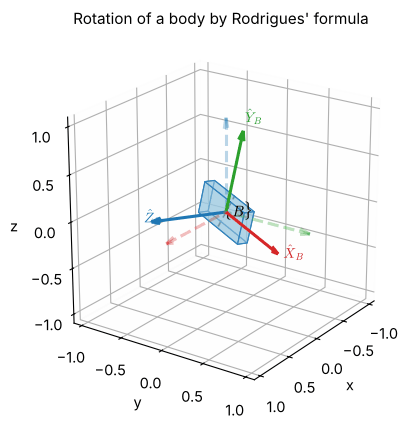

<IPython.core.display.Math object>

input: k = [0.663 0.557 0.5  ], theta = 100 deg   recovered: k = [0.663 0.557 0.5  ], theta = 100.0 deg


In [3]:
def explore_rodrigues(azimuth=40.0, elevation=30.0, angle=100.0):
    k = np.array([np.cos(deg(elevation)) * np.cos(deg(azimuth)), np.cos(deg(elevation)) * np.sin(deg(azimuth)), np.sin(deg(elevation))])
    R = rot_axis_angle(k, deg(angle))
    ax = new_axes3d(lim=1.1, title=r"Rotation of a body by Rodrigues' formula", figsize=(4.8, 4.8))
    draw_frame(ax, np.eye(3), name="A", alpha=0.3, ls="--", label_axes=False)
    draw_frame(ax, R, name="B", length=0.9)
    draw_box(ax, np.block([[R, np.zeros((3, 1))], [0, 0, 0, 1]]), size=(0.7, 0.35, 0.12))
    ax.plot(*np.outer([-1.1, 1.1], k).T, "k--", lw=1.4)
    plt.show()
    display(Math(matrix_to_latex(R, 3, r"R")))
    k2, th2 = axis_angle_from_rot(R)
    print(f"input: k = {k.round(3)}, theta = {angle:.0f} deg   recovered: k = {k2.round(3)}, theta = {np.degrees(th2):.1f} deg")

interact(explore_rodrigues,
         azimuth=widgets.FloatSlider(40, min=-180, max=180, step=5, description="azimuth (°)"),
         elevation=widgets.FloatSlider(30, min=-90, max=90, step=5, description="elevation (°)"),
         angle=widgets.FloatSlider(100, min=0, max=360, step=5, description="angle θ (°)"));

## 3. The inverse problem: from a matrix to an axis and an angle

Given a numerical rotation matrix $R$, we want $(\hat k,\theta)$. Taking the trace of Rodrigues' formula,
$\operatorname{tr}R = 1+2\cos\theta$ (the eigenvalues are $1, e^{\pm i\theta}$); taking its skew-symmetric part,
$R-R^{\mathsf T} = 2\sin\theta\,[\hat k]_\times$, because $\hat k\hat k^{\mathsf T}$ and $I$ are symmetric. Hence

$$
\cos\theta = \tfrac12(\operatorname{tr}R-1),\qquad
\sin\theta\;\hat k = \tfrac12\begin{bmatrix}r_{32}-r_{23}\\ r_{13}-r_{31}\\ r_{21}-r_{12}\end{bmatrix}\equiv\mathbf v .
$$

Since $\sin\theta\ge0$ for $0\le\theta\le\pi$, we have $\sin\theta=\lVert\mathbf v\rVert$ and $\hat k=\mathbf v/\lVert\mathbf v\rVert$
(Craig eqs. 2.81–2.82 give the same result with $\theta=\arccos\frac{\operatorname{tr}R-1}{2}$). Two practical remarks.

* **Use `atan2` for the angle.** $\theta = \arccos\big((\operatorname{tr}R-1)/2\big)$ is ill-conditioned near $\theta=0$ and
  $\theta=\pi$, where the cosine is flat: a rounding error of size $\varepsilon$ in the trace becomes an error of order
  $\sqrt\varepsilon\approx10^{-8}$ in the angle. $\theta=\operatorname{atan2}(\lVert\mathbf v\rVert,\ \tfrac12(\operatorname{tr}R-1))$ is accurate everywhere.
* **The two singular cases.** If $\theta=0$ ($\mathbf v=\mathbf 0$, $R=I$) the axis is arbitrary. If $\theta=\pi$ then
  $\sin\theta=0$ and $\mathbf v$ vanishes, but $R=2\hat k\hat k^{\mathsf T}-I$, so $\hat k\hat k^{\mathsf T}=(R+I)/2$: read $\hat k$
  from the column of $(R+I)/2$ with the largest diagonal entry (the sign of $\hat k$ is then arbitrary, because $\pm\hat k$ give the same rotation).

The function below is implemented from scratch and compared with the naive arccos formula over a range of angles.

In [4]:
def axis_angle_from_R(R, tol=1e-9):
    """(k, theta) with 0 <= theta <= pi, accurate for every rotation angle."""
    v = unskew(R - R.T) / 2.0                          # = sin(theta) k
    s, c = np.linalg.norm(v), (np.trace(R) - 1.0) / 2.0
    theta = np.arctan2(s, c)
    if s > tol:
        return v / s, theta
    if c > 0:                                          # theta ~ 0: the axis is arbitrary
        return np.array([0.0, 0.0, 1.0]), theta
    B = (R + np.eye(3)) / 2.0                          # theta ~ pi: B = k k^T
    i = int(np.argmax(np.diag(B)))
    return B[:, i] / np.sqrt(B[i, i]), theta

def theta_naive(R):
    return np.arccos((np.trace(R) - 1) / 2)

k0 = np.array([1.0, 2.0, 2.0]) / 3.0
rows = ["| true θ | arccos formula: error | atan2 formula: error | axis error |", "|:--|--:|--:|--:|"]
for t_true in (1e-9, 1e-6, 1e-3, 1.0, np.pi - 1e-3, np.pi - 1e-6, np.pi - 1e-9, np.pi):
    R = rot_axis_angle(k0, t_true)
    kk, tt = axis_angle_from_R(R)
    err_axis = min(np.linalg.norm(kk - k0), np.linalg.norm(kk + k0))
    rows.append(f"| {t_true:.9f} | {abs(theta_naive(R) - t_true):.1e} | {abs(tt - t_true):.1e} | {err_axis:.1e} |")
display(Markdown("\n".join(rows)))

Rs = Rot.random(2000, random_state=5).as_matrix()
worst = max(abs(rot_axis_angle(*axis_angle_from_R(R)) - R).max() for R in Rs)
print("round trip R -> (k, theta) -> R over 2000 random rotations, worst entry error:", f"{worst:.1e}")
print("agrees with rgkit.axis_angle_from_rot:", all(np.allclose(axis_angle_from_R(R)[0], axis_angle_from_rot(R)[0], atol=1e-7)
                                                   and np.isclose(axis_angle_from_R(R)[1], axis_angle_from_rot(R)[1]) for R in Rs))

/tmp/ipykernel_19605/2121634766.py:15: RuntimeWarning: invalid value encountered in arccos
  return np.arccos((np.trace(R) - 1) / 2)


| true θ | arccos formula: error | atan2 formula: error | axis error |
|:--|--:|--:|--:|
| 0.000000001 | 1.0e-09 | 0.0e+00 | 8.2e-01 |
| 0.000001000 | 4.4e-11 | 2.1e-22 | 0.0e+00 |
| 0.001000000 | 7.8e-15 | 2.2e-19 | 0.0e+00 |
| 1.000000000 | 1.1e-16 | 0.0e+00 | 0.0e+00 |
| 3.140592654 | 4.5e-13 | 0.0e+00 | 5.2e-14 |
| 3.141591654 | 4.0e-10 | 0.0e+00 | 2.6e-11 |
| 3.141592653 | nan | 0.0e+00 | 2.6e-08 |
| 3.141592654 | nan | 0.0e+00 | 3.5e-16 |

round trip R -> (k, theta) -> R over 2000 random rotations, worst entry error: 2.0e-14


agrees with rgkit.axis_angle_from_rot: True


## 4. Exponential coordinates and the matrix logarithm

There is a more systematic way to arrive at Rodrigues' formula, and it opens the door to Lie-group methods
(later in this chapter and in Chapter 3). Suppose a body rotates with constant angular velocity $\hat\omega$ about a fixed unit axis,
so that $\dot{\mathbf p}(t) = \hat\omega\times\mathbf p(t) = [\hat\omega]_\times\mathbf p(t)$. This is a linear differential
equation with solution $\mathbf p(t) = e^{[\hat\omega]_\times t}\mathbf p(0)$, where the **matrix exponential** is defined by the power series

$$
e^{A} = I + A + \frac{A^2}{2!} + \frac{A^3}{3!} + \cdots .
$$

After a time $t=\theta$ the vector has turned through the angle $\theta$, so the rotation matrix is
$R = e^{[\hat\omega]_\times\theta}$. The skew matrix of a *unit* vector satisfies $[\hat\omega]_\times^3 = -[\hat\omega]_\times$
(because $[\hat\omega]_\times^2 = \hat\omega\hat\omega^{\mathsf T}-I$ and $[\hat\omega]_\times\hat\omega=\mathbf 0$), hence all odd powers reduce to $\pm[\hat\omega]_\times$ and all even powers to $\pm[\hat\omega]_\times^2$:

$$
e^{[\hat\omega]_\times\theta} = I + \Big(\theta-\frac{\theta^3}{3!}+\cdots\Big)[\hat\omega]_\times + \Big(\frac{\theta^2}{2!}-\frac{\theta^4}{4!}+\cdots\Big)[\hat\omega]_\times^2
= I + \sin\theta\,[\hat\omega]_\times + (1-\cos\theta)[\hat\omega]_\times^2 ,
$$

which is **exactly Rodrigues' formula**. The three-vector $\boldsymbol r = \hat\omega\theta\in\mathbb R^3$ is called the
**exponential coordinates** (or rotation vector) of $R$, and $R = \exp([\boldsymbol r]_\times)$. The inverse map is the **matrix logarithm**:

$$
\log R = [\hat\omega]_\times\theta,\qquad \theta=\operatorname{atan2}\!\big(\lVert\mathbf v\rVert,\tfrac12(\operatorname{tr}R-1)\big),\quad
[\hat\omega]_\times = \frac{R-R^{\mathsf T}}{2\sin\theta},
$$

with the special cases $\log I=0$ and, for $\theta=\pi$, the axis of Section 3. These are the same formulae as before;
they just have a new name and a new meaning: exponentiation maps a skew-symmetric matrix (the Lie algebra
$\mathfrak{so}(3)$) onto $SO(3)$. The cell checks the series, the identity $[\hat\omega]^3=-[\hat\omega]$ and the
logarithm against SciPy's `expm` and `logm`.

In [5]:
w = np.array([2.0, -1.0, 2.0]) / 3.0; theta = deg(110)
W = skew(w)
print("[w]^3 = -[w] :", np.allclose(W @ W @ W, -W))
partial = lambda n: sum(np.linalg.matrix_power(W * theta, m) / np.math.factorial(m) if hasattr(np, "math") else
                        np.linalg.matrix_power(W * theta, m) / float(np.prod(range(1, m + 1)) if m else 1) for m in range(n + 1))
for n in (2, 4, 6, 10):
    print(f"power series truncated after {n:2d} terms: error {abs(partial(n) - rot_axis_angle(w, theta)).max():.1e}")
print("scipy expm([w] theta) equals Rodrigues:", np.allclose(expm(W * theta), rot_axis_angle(w, theta)))

R = rot_axis_angle(w, theta)
L = np.real(logm(R))                                              # logm returns a complex array with zero imaginary part
print("scipy logm(R) = [w] theta:", np.allclose(L, W * theta), "  our (k, theta) from R:", [x.round(4) for x in axis_angle_from_R(R)])
r_vec = unskew(L); print("exponential coordinates r = theta*w =", r_vec.round(4), " |r| =", np.linalg.norm(r_vec).round(4), "rad =",
                         np.degrees(np.linalg.norm(r_vec)).round(2), "deg")

[w]^3 = -[w] : True
power series truncated after  2 terms: error 7.6e-01
power series truncated after  4 terms: error 1.5e-01
power series truncated after  6 terms: error 1.3e-02
power series truncated after 10 terms: error 2.2e-05
scipy expm([w] theta) equals Rodrigues: True
scipy logm(R) = [w] theta: True   our (k, theta) from R: [array([ 0.6667, -0.3333,  0.6667]), np.float64(1.9199)]
exponential coordinates r = theta*w = [ 1.2799 -0.64    1.2799]  |r| = 1.9199 rad = 110.0 deg


**The topology of rotations.** Because every rotation has a representative with $\lVert\boldsymbol r\rVert\le\pi$, the group
$SO(3)$ can be pictured as a **solid ball of radius $\pi$** in exponential coordinates, with the *antipodal points on the
surface identified* ($\pi\hat k$ and $-\pi\hat k$ are the same rotation). Rotate about a fixed axis from $\theta=0$ to
$2\pi$: the point $\theta\hat k$ leaves the centre, reaches the surface at $\theta=\pi$, **reappears at the opposite point of the
surface**, and travels back to the centre. A smooth closed path of rotations therefore looks discontinuous in this
chart: a symptom of the fact that no three-parameter chart of $SO(3)$ is free of singularities (Section 2.4).

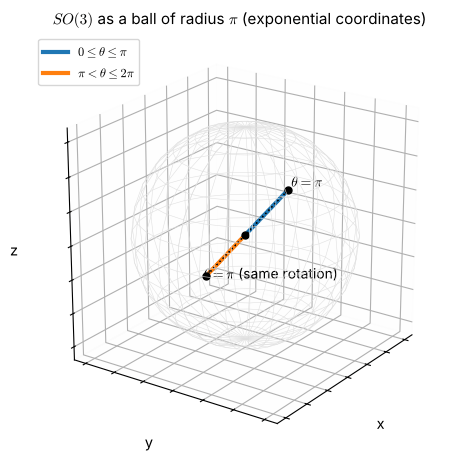

exp(pi k) and exp(-pi k) are the same rotation: True


In [6]:
kd = np.array([1.0, 2.0, 2.0]) / 3.0
th_up = np.linspace(0, np.pi, 40); th_down = np.linspace(np.pi, 2 * np.pi, 40)
leg1 = np.outer(th_up, kd).T                              # principal rotation vector for 0 <= theta <= pi
leg2 = np.outer(th_down - 2 * np.pi, kd).T               # for pi < theta < 2 pi the principal vector is (theta - 2 pi) k
ax = new_axes3d(lim=3.4, title=r"$SO(3)$ as a ball of radius $\pi$ (exponential coordinates)", azim=35, elev=22, figsize=(5.6, 5.4), ticks=False)
uu, vv = np.mgrid[0:2 * np.pi:30j, 0:np.pi:15j]
ax.plot_wireframe(np.pi * np.cos(uu) * np.sin(vv), np.pi * np.sin(uu) * np.sin(vv), np.pi * np.cos(vv), color="0.88", lw=0.4)
ax.plot(*leg1, color="#1f77b4", lw=3, label=r"$0\leq\theta\leq\pi$"); ax.plot(*leg2, color="#ff7f0e", lw=3, label=r"$\pi<\theta\leq2\pi$")
ax.plot(*np.array([np.pi * kd, -np.pi * kd]).T, "k:", lw=1.2)
ax.scatter(*(np.pi * kd), color="k", s=25); ax.scatter(*(-np.pi * kd), color="k", s=25); ax.scatter(0, 0, 0, color="k", s=25)
ax.text(*(1.08 * np.pi * kd), r"$\theta=\pi$", fontsize=10); ax.text(*(-1.08 * np.pi * kd), r"$\theta=\pi$ (same rotation)", fontsize=10)
ax.legend(loc="upper left", fontsize=9)
plt.show()
r_a, r_b = np.pi * kd, -np.pi * kd
print("exp(pi k) and exp(-pi k) are the same rotation:", np.allclose(rot_axis_angle(kd, np.pi), rot_axis_angle(-kd, np.pi)))

## 5. Quaternion algebra

**Why a new number system?** A unit axis and an angle are awkward to *compose*: Rodrigues' formula gives the matrix
of one rotation, but combining two angle–axis pairs into a third needs a matrix product followed by an extraction. The
quaternions, introduced by W. R. Hamilton in 1843, provide a four-component number whose *product* corresponds to composing rotations.

A **quaternion** is
$$ q = s + x\,\mathrm{i} + y\,\mathrm{j} + z\,\mathrm{k} = (s,\ \mathbf v),\qquad \mathbf v = (x,y,z), $$
with a scalar part $s$ and a vector part $\mathbf v$, where the three imaginary units obey **Hamilton's rule**
$$ \mathrm{i}^2=\mathrm{j}^2=\mathrm{k}^2=\mathrm{ijk}=-1 . $$
Everything else follows. Multiplying $\mathrm{ijk}=-1$ on the right by $\mathrm k$ gives $\mathrm{ij}\,\mathrm k^2=-\mathrm k$, i.e.
$\mathrm{ij}=\mathrm k$; similarly $\mathrm{jk}=\mathrm i$, $\mathrm{ki}=\mathrm j$; and, because $\mathrm i(\mathrm{ij})=\mathrm i\mathrm k$ while also
$(\mathrm{ii})\mathrm j=-\mathrm j$, reversing the order flips the sign: $\mathrm{ji}=-\mathrm k$, $\mathrm{kj}=-\mathrm i$, $\mathrm{ik}=-\mathrm j$.
The pattern is the pattern of the cross product $\hat X\times\hat Y=\hat Z$ (plus $-1$ for a unit times itself).

Multiplying two quaternions term by term then gives (the scalar–scalar part $s_1s_2$, the mixed parts $s_1\mathbf v_2+s_2\mathbf v_1$, and
the vector–vector part, which is $-\mathbf v_1\cdot\mathbf v_2$ from $\mathrm i^2=-1$ etc. plus $\mathbf v_1\times\mathbf v_2$ from $\mathrm{ij}=\mathrm k$ etc.):

> **Quaternion (Hamilton) product.**
> $$ q_1\otimes q_2 = \big(s_1s_2-\mathbf v_1\cdot\mathbf v_2,\ \ s_1\mathbf v_2+s_2\mathbf v_1+\mathbf v_1\times\mathbf v_2\big). $$

The product is **associative** and distributive but **not commutative**: swapping the factors flips the sign of the cross
product term, exactly like the non-commutativity of rotations. Further definitions:

| Quantity | Definition | Properties |
|:--|:--|:--|
| Conjugate | $q^*=(s,-\mathbf v)$ | $(q_1\otimes q_2)^*=q_2^*\otimes q_1^*$ (order reverses) |
| Norm | $\lVert q\rVert=\sqrt{q\otimes q^*}=\sqrt{s^2+x^2+y^2+z^2}$ | $\lVert q_1\otimes q_2\rVert=\lVert q_1\rVert\lVert q_2\rVert$ |
| Inverse | $q^{-1}=q^*/\lVert q\rVert^2$ | $q\otimes q^{-1}=(1,\mathbf 0)$ |
| Unit quaternion | $\lVert q\rVert=1$ | $q^{-1}=q^*$; the set is the unit sphere $S^3\subset\mathbb R^4$, closed under $\otimes$ |
| Pure quaternion | $(0,\mathbf p)$ | how an ordinary 3-vector is written as a quaternion |

The cell derives the product **independently** from the $4\times4$ multiplication table of the units $1,\mathrm i,\mathrm j,\mathrm k$
and compares it with the closed formula and with `rgkit`.

In [7]:
# multiplication table of the basis elements (1, i, j, k): entry [a][b] = (sign, index of the product)
TABLE = [[(1, 0), (1, 1), (1, 2), (1, 3)],
         [(1, 1), (-1, 0), (1, 3), (-1, 2)],
         [(1, 2), (-1, 3), (-1, 0), (1, 1)],
         [(1, 3), (1, 2), (-1, 1), (-1, 0)]]

def qmul_table(q1, q2):
    out = np.zeros(4)
    for a in range(4):
        for b in range(4):
            sign, idx = TABLE[a][b]
            out[idx] += sign * q1[a] * q2[b]
    return out

def qmul_formula(q1, q2):
    s1, v1, s2, v2 = q1[0], np.asarray(q1[1:]), q2[0], np.asarray(q2[1:])
    return np.concatenate([[s1 * s2 - v1 @ v2], s1 * v2 + s2 * v1 + np.cross(v1, v2)])

rng = np.random.default_rng(2)
q1, q2, q3 = rng.normal(size=(3, 4))
print("table product == formula == rgkit.quat_mul:",
      np.allclose(qmul_table(q1, q2), qmul_formula(q1, q2)) and np.allclose(qmul_formula(q1, q2), quat_mul(q1, q2)))
print("associative:", np.allclose(qmul_formula(qmul_formula(q1, q2), q3), qmul_formula(q1, qmul_formula(q2, q3))))
print("not commutative:", not np.allclose(qmul_formula(q1, q2), qmul_formula(q2, q1)),
      "  q1 q2 - q2 q1 = 2 v1 x v2 in the vector part:", np.allclose((qmul_formula(q1, q2) - qmul_formula(q2, q1))[1:], 2 * np.cross(q1[1:], q2[1:])))
print("(q1 q2)* = q2* q1*:", np.allclose(quat_conj(qmul_formula(q1, q2)), qmul_formula(quat_conj(q2), quat_conj(q1))))
print("|q1 q2| = |q1||q2|:", np.isclose(np.linalg.norm(qmul_formula(q1, q2)), np.linalg.norm(q1) * np.linalg.norm(q2)))
print("q q* = (|q|^2, 0):", qmul_formula(q1, quat_conj(q1)).round(10), " |q1|^2 =", (q1 @ q1).round(10))
print("i j = k:", qmul_table([0, 1, 0, 0], [0, 0, 1, 0]), "   j i = -k:", qmul_table([0, 0, 1, 0], [0, 1, 0, 0]))

table product == formula == rgkit.quat_mul: True
associative: True
not commutative: True   q1 q2 - q2 q1 = 2 v1 x v2 in the vector part: True
(q1 q2)* = q2* q1*: True
|q1 q2| = |q1||q2|: True
q q* = (|q|^2, 0): [6.4404 0.     0.     0.    ]  |q1|^2 = 6.4403915856
i j = k: [0. 0. 0. 1.]    j i = -k: [ 0.  0.  0. -1.]


**Cost.** A quaternion product needs 16 multiplications and 12 additions; a $3\times3$ matrix product needs 27 multiplications
and 18 additions. A unit quaternion stores four numbers instead of nine. These savings, and the cheap repair of rounding error
(Section 9), are why embedded systems, inertial sensors and graphics engines store orientation as quaternions.

## 6. Unit quaternions as rotations

**The rotation quaternion.** A rotation through $\theta$ about the unit axis $\hat k$ is represented by the unit quaternion

$$
q = \Big(\cos\frac\theta2,\ \ \hat k\,\sin\frac\theta2\Big),
$$

and a vector $\mathbf p$, written as the pure quaternion $(0,\mathbf p)$, is rotated by the **sandwich product**

$$
(0,\ \mathbf p') = q\otimes(0,\mathbf p)\otimes q^{*}.
$$

*Derivation.* Put $c=\cos\frac\theta2$ and $s=\sin\frac\theta2$, so $q=(c,\ s\hat k)$. First,
$q\otimes(0,\mathbf p) = \big(-s\,\hat k\cdot\mathbf p,\ \ c\,\mathbf p+s\,\hat k\times\mathbf p\big)$. Multiplying by $q^*=(c,-s\hat k)$ on the right,
the scalar part cancels and the vector part is
$$
c^2\mathbf p + cs\,\hat k\times\mathbf p + s^2(\hat k\cdot\mathbf p)\hat k - cs\,\mathbf p\times\hat k\cdot(\ldots)
= (c^2-s^2)\,\mathbf p + 2s^2(\hat k\cdot\mathbf p)\,\hat k + 2cs\,(\hat k\times\mathbf p),
$$
where the terms were collected with the "bac–cab" rule. With $c^2-s^2=\cos\theta$, $2s^2=1-\cos\theta$ and $2cs=\sin\theta$ this is
$\cos\theta\,\mathbf p+(1-\cos\theta)(\hat k\cdot\mathbf p)\hat k+\sin\theta\,\hat k\times\mathbf p$ — Rodrigues' formula. $\blacksquare$
The **half angle** appears because $q$ acts on $\mathbf p$ twice, once from each side.

**Composition.** If $R = R_1R_2$ (rotation $R_2$ first in the operator reading, as in Section 2.2), then
$q = q_1\otimes q_2$, with the *same order* as the matrices; the inverse rotation is $q^{*}$.

**The double cover.** Replace $q$ by $-q$: the sandwich $(-q)\otimes(0,\mathbf p)\otimes(-q)^*$ is unchanged, since the sign appears twice. Hence
$q$ and $-q$ are **the same rotation**; equivalently $\theta$ and $\theta+2\pi$ give quaternions of opposite sign. The unit sphere $S^3$
covers $SO(3)$ exactly **twice**. A rotation by $2\pi$ about any axis is the identity *matrix*, but takes the quaternion
from $(1,\mathbf 0)$ to $(-1,\mathbf 0)$; only after $4\pi$ does the quaternion return. Practical consequence: before averaging or
interpolating two quaternions, flip one of them if their dot product is negative (Section 8).

*Craig's Euler parameters* $\epsilon_1,\epsilon_2,\epsilon_3,\epsilon_4$ are the same four numbers written **scalar last**:
$\epsilon_{1..3}=\hat k\sin\frac\theta2$, $\epsilon_4=\cos\frac\theta2$ (Craig eqs. 2.89–2.90). Libraries differ: this repository, MuJoCo and
`rgkit` use $(w,x,y,z)$; ROS messages and SciPy's `as_quat()` use $(x,y,z,w)$. *Always check where the scalar sits.*

q = [ 0.4226  0.3955 -0.7911  0.1978]   |q| = 1.0
sandwich q (0,p) q* == Rodrigues: True   == quat_rotate: True
scalar part of the sandwich is 0: True
R(q1 q2) == R(q1) R(q2): True    R(q1* ) == R(q1)^T: True
q and -q are the same rotation: True


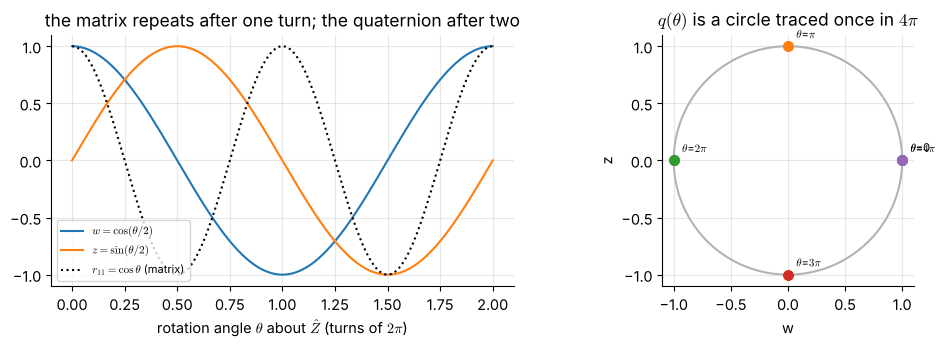

In [8]:
k = np.array([1.0, -2.0, 0.5]); k /= np.linalg.norm(k); theta = deg(130); p = np.array([0.4, 1.1, -0.7])
q = quat_from_axis_angle(k, theta)
print("q =", q.round(4), "  |q| =", np.linalg.norm(q).round(12))
print("sandwich q (0,p) q* == Rodrigues:", np.allclose(qmul_formula(qmul_formula(q, np.r_[0, p]), quat_conj(q))[1:], rot_axis_angle(k, theta) @ p),
      "  == quat_rotate:", np.allclose(quat_rotate(q, p), rot_axis_angle(k, theta) @ p))
print("scalar part of the sandwich is 0:", np.isclose(qmul_formula(qmul_formula(q, np.r_[0, p]), quat_conj(q))[0], 0))

# composition: R = R1 R2  <->  q = q1 q2 (same order)
ka, kb = np.array([1.0, 0, 0]), np.array([0.0, 1, 1]) / np.sqrt(2)
qa, qb = quat_from_axis_angle(ka, deg(70)), quat_from_axis_angle(kb, deg(-40))
print("R(q1 q2) == R(q1) R(q2):", np.allclose(quat_to_rot(qmul_formula(qa, qb)), quat_to_rot(qa) @ quat_to_rot(qb)),
      "   R(q1* ) == R(q1)^T:", np.allclose(quat_to_rot(quat_conj(qa)), quat_to_rot(qa).T))
print("q and -q are the same rotation:", np.allclose(quat_to_rot(q), quat_to_rot(-q)))

# the double cover: a full turn about z
th = np.linspace(0, 4 * np.pi, 401)
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6))
axs[0].plot(th / (2 * np.pi), np.cos(th / 2), label=r"$w=\cos(\theta/2)$"); axs[0].plot(th / (2 * np.pi), np.sin(th / 2), label=r"$z=\sin(\theta/2)$")
axs[0].plot(th / (2 * np.pi), np.cos(th), "k:", label=r"$r_{11}=\cos\theta$ (matrix)")
axs[0].set_xlabel(r"rotation angle $\theta$ about $\hat Z$ (turns of $2\pi$)"); axs[0].legend(fontsize=8, loc="lower left"); axs[0].set_title("the matrix repeats after one turn; the quaternion after two")
axs[1].plot(np.cos(th / 2), np.sin(th / 2), color="0.7")
for n, lab in zip(range(5), ["0", r"$\pi$", r"$2\pi$", r"$3\pi$", r"$4\pi$"]):
    t_ = n * np.pi; axs[1].plot(np.cos(t_ / 2), np.sin(t_ / 2), "o", ms=7); axs[1].annotate(rf"$\theta$={lab}", (np.cos(t_ / 2), np.sin(t_ / 2)),
                                                                                         textcoords="offset points", xytext=(6, 6), fontsize=8)
axs[1].set_aspect("equal"); axs[1].set_xlabel("w"); axs[1].set_ylabel("z"); axs[1].set_title(r"$q(\theta)$ is a circle traced once in $4\pi$")
fig.tight_layout(); plt.show()

## 7. Conversions between representations

**Quaternion to matrix (Craig eq. 2.91).** For a unit quaternion $q=(w,x,y,z)$, expanding the sandwich product gives

$$
R(q)=\begin{bmatrix}1-2(y^2+z^2) & 2(xy-wz) & 2(xz+wy)\\ 2(xy+wz) & 1-2(x^2+z^2) & 2(yz-wx)\\ 2(xz-wy) & 2(yz+wx) & 1-2(x^2+y^2)\end{bmatrix}.
$$

**Matrix to quaternion (Craig eq. 2.92).** The trace and the diagonal give the *squares* of the components,
$$
4w^2=1+r_{11}+r_{22}+r_{33},\quad 4x^2=1+r_{11}-r_{22}-r_{33},\quad 4y^2=1-r_{11}+r_{22}-r_{33},\quad 4z^2=1-r_{11}-r_{22}+r_{33},
$$
and the off-diagonal entries give the *products*: $r_{32}-r_{23}=4wx$, $r_{13}-r_{31}=4wy$, $r_{21}-r_{12}=4wz$, $r_{12}+r_{21}=4xy$,
$r_{13}+r_{31}=4xz$, $r_{23}+r_{32}=4yz$. Textbooks usually compute $w=\tfrac12\sqrt{1+\operatorname{tr}R}$ and then
$x=(r_{32}-r_{23})/4w$, etc. This **fails near $\theta=\pi$**, where $w\to0$ and the divisions amplify rounding errors without bound.
The robust method (Shepperd's) picks the *largest* of $4w^2,4x^2,4y^2,4z^2$ — at least $1$ — takes its square root, and obtains the other three components
from the products, so the divisor is never small. The sign is fixed by requiring $w\ge0$ (the two quaternions $\pm q$ are the same rotation).

**Angle–axis and quaternion.** $q=(\cos\frac\theta2,\ \hat k\sin\frac\theta2)$, and conversely
$\theta=2\operatorname{atan2}(\lVert\mathbf v\rVert,\ s)$, $\hat k=\mathbf v/\lVert\mathbf v\rVert$.

**Roll–pitch–yaw and quaternion.** Since $R=R_Z(\alpha)R_Y(\beta)R_X(\gamma)$, the quaternion is the product
$q=q_Z(\alpha)\otimes q_Y(\beta)\otimes q_X(\gamma)$ of three single-axis quaternions. Multiplying them symbolically:

In [9]:
# symbolic product q = q_z(alpha) x q_y(beta) x q_x(gamma) with half-angle symbols
ha, hb, hg = sp.symbols(r"\alpha_h \beta_h \gamma_h", real=True)         # half angles alpha/2, beta/2, gamma/2
qz = sp.Matrix([sp.cos(ha), 0, 0, sp.sin(ha)]); qy = sp.Matrix([sp.cos(hb), 0, sp.sin(hb), 0]); qx = sp.Matrix([sp.cos(hg), sp.sin(hg), 0, 0])

def qmul_sym(a, b):
    s1, v1, s2, v2 = a[0], sp.Matrix(a[1:]), b[0], sp.Matrix(b[1:])
    return sp.Matrix([s1 * s2 - (v1.T * v2)[0]] + list(s1 * v2 + s2 * v1 + v1.cross(v2)))

q_rpy = sp.simplify(qmul_sym(qmul_sym(qz, qy), qx))
display(Math(r"q_{RPY}= " + sp.latex(sp.Matrix(q_rpy))))

# the inverse formulas used by IMU and drone software, implemented and tested
def rpy_from_quat(q):
    w, x, y, z = q / np.linalg.norm(q)
    roll = np.arctan2(2 * (w * x + y * z), 1 - 2 * (x * x + y * y))
    pitch = np.arcsin(np.clip(2 * (w * y - z * x), -1.0, 1.0))
    yaw = np.arctan2(2 * (w * z + x * y), 1 - 2 * (y * y + z * z))
    return roll, pitch, yaw

def quat_from_rpy(roll, pitch, yaw):
    return quat_mul(quat_mul(quat_from_axis_angle([0, 0, 1], yaw), quat_from_axis_angle([0, 1, 0], pitch)), quat_from_axis_angle([1, 0, 0], roll))

g_, b_, a_ = deg(25), deg(-40), deg(110)
f = sp.lambdify((ha, hb, hg), q_rpy, "numpy")
print("symbolic product agrees with quat_from_rpy:", np.allclose(np.ravel(f(a_ / 2, b_ / 2, g_ / 2)), quat_from_rpy(g_, b_, a_)))
print("rpy_from_quat recovers (roll, pitch, yaw) =", np.degrees(rpy_from_quat(quat_from_rpy(g_, b_, a_))).round(4), "deg")
print("quat_to_rot(quat_from_rpy) == rpy_to_rot:", np.allclose(quat_to_rot(quat_from_rpy(g_, b_, a_)), rpy_to_rot(g_, b_, a_)))

<IPython.core.display.Math object>

symbolic product agrees with quat_from_rpy: True
rpy_from_quat recovers (roll, pitch, yaw) = [ 25. -40. 110.] deg
quat_to_rot(quat_from_rpy) == rpy_to_rot: True


In [10]:
def R_from_quat(q):
    w, x, y, z = q / np.linalg.norm(q)
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)],
                     [2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)],
                     [2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)]])

def quat_from_R_naive(R):
    w = 0.5 * np.sqrt(max(1.0 + np.trace(R), 0.0))
    return np.array([w, (R[2, 1] - R[1, 2]) / (4 * w), (R[0, 2] - R[2, 0]) / (4 * w), (R[1, 0] - R[0, 1]) / (4 * w)])

def quat_from_R(R):
    """Shepperd's method: divide only by the largest of 2w, 2x, 2y, 2z."""
    sq = 0.25 * np.array([1 + np.trace(R), 1 + R[0, 0] - R[1, 1] - R[2, 2], 1 - R[0, 0] + R[1, 1] - R[2, 2], 1 - R[0, 0] - R[1, 1] + R[2, 2]])
    i = int(np.argmax(sq)); q = np.zeros(4); q[i] = np.sqrt(sq[i])
    if i == 0:   q[1:] = [R[2, 1] - R[1, 2], R[0, 2] - R[2, 0], R[1, 0] - R[0, 1]] / (4 * q[0])
    elif i == 1: q[[0, 2, 3]] = np.array([R[2, 1] - R[1, 2], R[0, 1] + R[1, 0], R[0, 2] + R[2, 0]]) / (4 * q[1])
    elif i == 2: q[[0, 1, 3]] = np.array([R[0, 2] - R[2, 0], R[0, 1] + R[1, 0], R[1, 2] + R[2, 1]]) / (4 * q[2])
    else:        q[[0, 1, 2]] = np.array([R[1, 0] - R[0, 1], R[0, 2] + R[2, 0], R[1, 2] + R[2, 1]]) / (4 * q[3])
    return q if q[0] >= 0 else -q

Rs = Rot.random(3000, random_state=9).as_matrix()
print("round trip R -> q -> R, worst entry error:", f"{max(abs(R_from_quat(quat_from_R(R)) - R).max() for R in Rs):.1e}",
      "  agrees with rgkit.rot_to_quat:", all(np.allclose(quat_from_R(R), rot_to_quat(R)) for R in Rs))
print("R_from_quat agrees with rgkit.quat_to_rot:", all(np.allclose(R_from_quat(q), quat_to_rot(q)) for q in rng.normal(size=(100, 4))))

rows = ["| rotation angle | error of the naive formula | error of Shepperd's method |", "|:--|--:|--:|"]
for dth in (1e-3, 1e-6, 1e-8, 1e-10):
    R = rot_axis_angle([1, 2, 2], np.pi - dth); q_true = quat_from_axis_angle([1, 2, 2], np.pi - dth)
    rows.append(f"| π − {dth:.0e} | {np.linalg.norm(quat_from_R_naive(R) - q_true):.1e} | {np.linalg.norm(quat_from_R(R) - q_true):.1e} |")
display(Markdown("\n".join(rows)))

round trip R -> q -> R, worst entry error: 8.9e-16   agrees with rgkit.rot_to_quat: True
R_from_quat agrees with rgkit.quat_to_rot: True


| rotation angle | error of the naive formula | error of Shepperd's method |
|:--|--:|--:|
| π − 1e-03 | 2.1e-10 | 1.1e-17 |
| π − 1e-06 | 2.7e-04 | 1.3e-16 |
| π − 1e-08 | 5.3e-01 | 8.2e-18 |
| π − 1e-10 | 1.0e+00 | 2.0e-17 |

## 8. Interpolating orientations: SLERP versus Euler angles

A robot must often move its tool smoothly from one orientation $R_0$ to another $R_1$. What should the intermediate orientations be?

* **Interpolating the entries of the matrix** does not give rotation matrices at all.
* **Interpolating three Euler angles** linearly, $\boldsymbol\theta(t)=(1-t)\boldsymbol\theta_0+t\boldsymbol\theta_1$, gives rotation matrices, but the path is neither the shortest nor of uniform speed. It depends on the convention, it takes the long way round whenever angles wrap (a roll of $-179^\circ$ and one of $+179^\circ$ differ by $2^\circ$, not $358^\circ$), and it behaves wildly near gimbal lock.
* **Spherical linear interpolation (SLERP)** moves along the great-circle arc of the quaternion sphere at constant speed:

$$
q(t)=\frac{\sin\big((1-t)\Omega\big)}{\sin\Omega}\,q_0+\frac{\sin(t\Omega)}{\sin\Omega}\,q_1,\qquad \cos\Omega=q_0\cdot q_1,\quad t\in[0,1].
$$

If $q_0\cdot q_1<0$, replace $q_1$ by $-q_1$ first (the same rotation) so that the **shorter** arc is taken. SLERP is equivalent to
$q(t)=q_0\otimes(q_0^{*}\otimes q_1)^{t}$, i.e. $R(t)=R_0\exp\!\big(t\,\log(R_0^{\mathsf T}R_1)\big)$: a **constant-speed rotation about one fixed axis**, the rotation that takes $R_0$ to $R_1$ the short way. Its angular speed is
$\theta_{01}/T$ throughout, where $\theta_{01}=2\Omega$ is the angle of $R_0^{\mathsf T}R_1$ — the *geodesic distance* between the orientations.

The cell proves the equivalence numerically and then compares the two methods on a pair of orientations chosen near the pole of the
roll–pitch–yaw convention. The angular speed of each interpolation is measured from the angle of the relative rotation between consecutive samples.

In [11]:
def slerp_R(R0, R1, t):
    return quat_to_rot(slerp(rot_to_quat(R0), rot_to_quat(R1), t))

def geodesic_R(R0, R1, t):
    """R0 exp(t log(R0^T R1)): constant-speed rotation about one fixed axis."""
    k_, th_ = axis_angle_from_R(R0.T @ R1)
    return R0 @ rot_axis_angle(k_, t * th_)

def euler_lerp_R(A, B, t):                                      # linear interpolation of (roll, pitch, yaw)
    return rpy_to_rot(*((1 - t) * np.asarray(A) + t * np.asarray(B)))

A = deg([-70.0, 85.0, -160.0]); B = deg([150.0, -10.0, 70.0])   # (roll, pitch, yaw) of start and goal
R0, R1 = rpy_to_rot(*A), rpy_to_rot(*B)
print("SLERP == R0 exp(t log(R0^T R1)) for 21 values of t:", all(np.allclose(slerp_R(R0, R1, t), geodesic_R(R0, R1, t)) for t in np.linspace(0, 1, 21)))
print("rgkit.slerp takes the short arc when q0.q1 < 0:", np.allclose(quat_to_rot(slerp(rot_to_quat(R0), -rot_to_quat(R1), 0.3)), slerp_R(R0, R1, 0.3)))

ts = np.linspace(0, 1, 201)
def speeds(Rfun):
    Rs_ = [Rfun(t) for t in ts]
    return np.array([axis_angle_from_R(Rs_[i].T @ Rs_[i + 1])[1] for i in range(len(ts) - 1)]) / (ts[1] - ts[0])
sp_slerp, sp_euler = speeds(lambda t: slerp_R(R0, R1, t)), speeds(lambda t: euler_lerp_R(A, B, t))
geo = axis_angle_from_R(R0.T @ R1)[1]
print(f"geodesic distance between the orientations: {np.degrees(geo):.1f} deg")
print(f"SLERP : path length {np.degrees(np.trapezoid(sp_slerp, ts[:-1])):6.1f} deg, speed between {np.degrees(sp_slerp.min()):6.1f} and {np.degrees(sp_slerp.max()):6.1f} deg per unit time")
print(f"Euler : path length {np.degrees(np.trapezoid(sp_euler, ts[:-1])):6.1f} deg, speed between {np.degrees(sp_euler.min()):6.1f} and {np.degrees(sp_euler.max()):6.1f} deg per unit time")
assert abs(np.trapezoid(sp_slerp, ts[:-1]) - geo) < 0.01 * geo and sp_euler.max() / sp_euler.min() > 3 and np.trapezoid(sp_euler, ts[:-1]) > 2 * geo

SLERP == R0 exp(t log(R0^T R1)) for 21 values of t: True
rgkit.slerp takes the short arc when q0.q1 < 0: True
geodesic distance between the orientations: 103.9 deg
SLERP : path length  103.4 deg, speed between  103.9 and  103.9 deg per unit time
Euler : path length  220.3 deg, speed between   97.7 and  357.0 deg per unit time


The animation shows the two interpolations of the figure side by side. The three coloured dotted curves are the paths that the tips of the
body's $\hat X$, $\hat Y$ and $\hat Z$ axes trace on the unit sphere. **SLERP** (right) sweeps each tip along a smooth
arc at constant speed; **linear Euler-angle interpolation** (left) takes a longer, curved detour with varying speed
and a very different set of intermediate frames. (In the published notebook the animation appears as a filmstrip; the GIF is in the
[chapter README](README.md).)

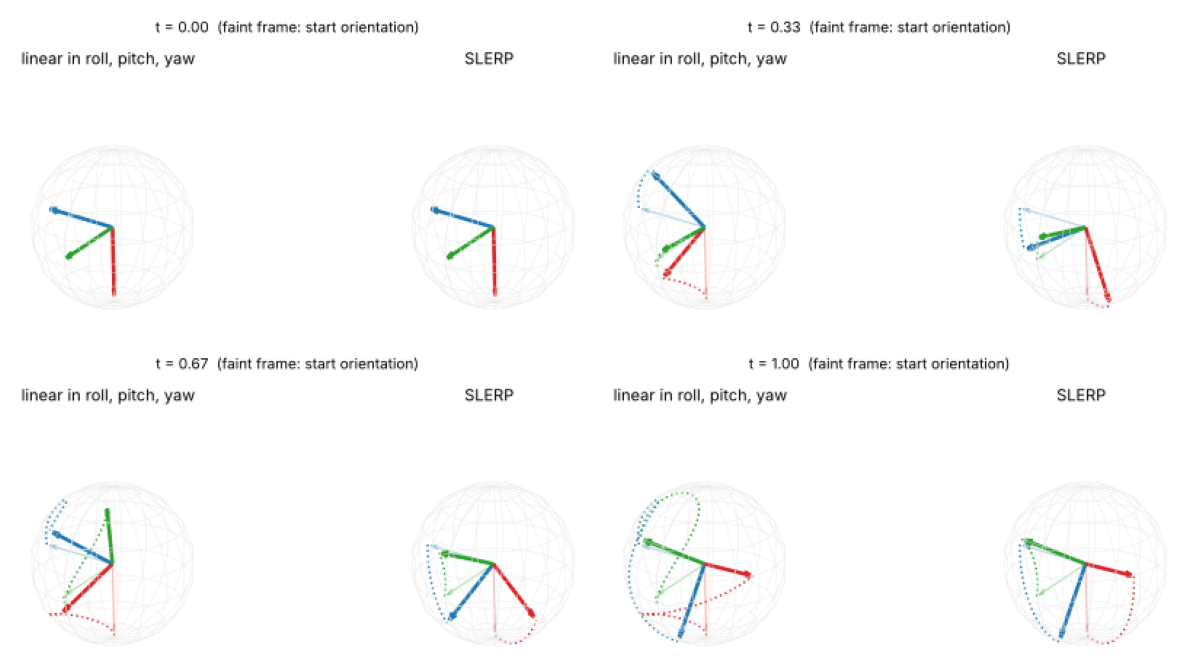

In [12]:
def trace_pts(Rfun, t_end):
    tt = np.linspace(0, t_end, max(int(60 * t_end) + 2, 2))
    return np.array([Rfun(t) for t in tt])                       # shape (n, 3, 3): columns are the axes

def draw_interp(ax, Rfun, t, title):
    ax.cla(); new_axes3d(ax, lim=1.15, title=title, ticks=False, azim=35, elev=22); ax.set_axis_off()
    uu, vv = np.mgrid[0:2 * np.pi:20j, 0:np.pi:10j]
    ax.plot_wireframe(np.cos(uu) * np.sin(vv), np.sin(uu) * np.sin(vv), np.cos(vv), color="0.92", lw=0.4)
    P = trace_pts(Rfun, t)
    for i, col in enumerate(AXIS_COLORS.values()):
        ax.plot(P[:, 0, i], P[:, 1, i], P[:, 2, i], color=col, lw=1.4, ls=":")
    draw_frame(ax, Rfun(t), length=0.95, label_axes=False, lw=2.6)
    draw_frame(ax, R0, length=0.95, label_axes=False, lw=1.2, alpha=0.3)

fig = plt.figure(figsize=(8.6, 4.2), dpi=72)
axL, axR = fig.add_subplot(121, projection="3d"), fig.add_subplot(122, projection="3d")
def update(t):
    draw_interp(axL, lambda s: euler_lerp_R(A, B, s), t, "linear in roll, pitch, yaw")
    draw_interp(axR, lambda s: slerp_R(R0, R1, s), t, "SLERP")
    fig.suptitle(f"t = {t:4.2f}  (faint frame: start orientation)", y=0.98, fontsize=10)
animate(fig, update, np.linspace(0, 1, 37), interval=100, gif="assets/2.5-slerp-vs-euler.gif")

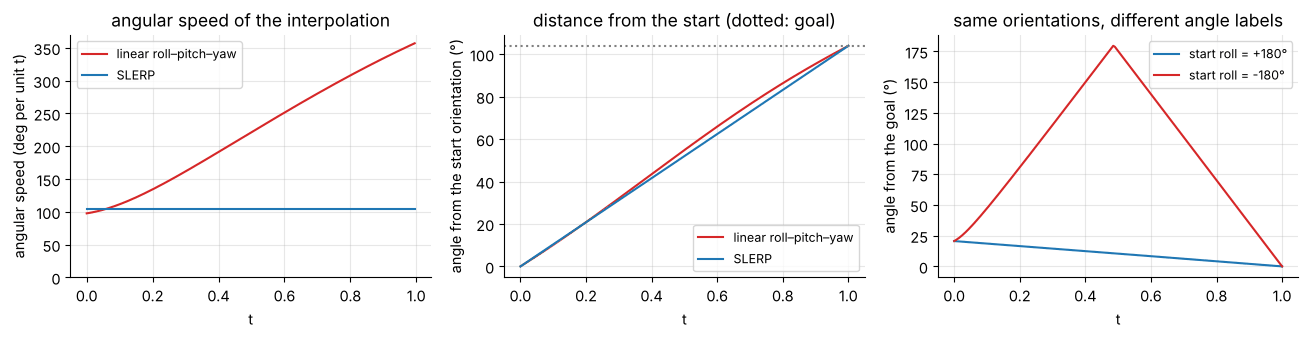

start roll +180 deg and -180 deg describe the same orientation: True


In [13]:
fig, axs = plt.subplots(1, 3, figsize=(13.2, 3.5))
axs[0].plot(ts[:-1], np.degrees(sp_euler), label="linear roll–pitch–yaw", color="#d62728"); axs[0].plot(ts[:-1], np.degrees(sp_slerp), label="SLERP", color="#1f77b4")
axs[0].set_xlabel("t"); axs[0].set_ylabel("angular speed (deg per unit t)"); axs[0].set_title("angular speed of the interpolation"); axs[0].legend(fontsize=9); axs[0].set_ylim(0, None)
E_path = np.array([np.degrees(rot_to_rpy(euler_lerp_R(A, B, t))) for t in ts])
axs[1].plot(ts, np.degrees(np.array([axis_angle_from_R(R0.T @ euler_lerp_R(A, B, t))[1] for t in ts])), color="#d62728", label="linear roll–pitch–yaw")
axs[1].plot(ts, np.degrees(np.array([axis_angle_from_R(R0.T @ slerp_R(R0, R1, t))[1] for t in ts])), color="#1f77b4", label="SLERP")
axs[1].axhline(np.degrees(geo), color="0.5", ls=":"); axs[1].set_xlabel("t"); axs[1].set_ylabel("angle from the start orientation (°)"); axs[1].set_title("distance from the start (dotted: goal)")
axs[1].legend(fontsize=9)
# a second failure mode: wrapped angles.  +180 deg and -180 deg of roll are the same orientation.
Rg = rpy_to_rot(deg(171.3), deg(18.1), deg(3.6))
for roll0, col in ((deg(180.0), "#1f77b4"), (deg(-180.0), "#d62728")):
    Ap, Bp = np.array([roll0, 0.0, 0.0]), np.array([deg(171.3), deg(18.1), deg(3.6)])
    axs[2].plot(ts, np.degrees([axis_angle_from_R(Rg.T @ euler_lerp_R(Ap, Bp, t))[1] for t in ts]), color=col, label=f"start roll = {np.degrees(roll0):+.0f}°")
axs[2].set_xlabel("t"); axs[2].set_ylabel("angle from the goal (°)"); axs[2].set_title("same orientations, different angle labels"); axs[2].legend(fontsize=9)
fig.tight_layout(); plt.show()
print("start roll +180 deg and -180 deg describe the same orientation:", np.allclose(rpy_to_rot(deg(180), 0, 0), rpy_to_rot(deg(-180), 0, 0)))

The right-hand panel shows the second classical failure: the orientations "roll $+180^\circ$" and "roll $-180^\circ$" are identical, yet linear
interpolation towards a goal with roll $171.3^\circ$ moves smoothly in one case and makes an almost complete turn about the $X$ axis in the
other. This is precisely the situation of the UR5e's tool in Section 2.4 (home pose: tool pointing down, roll $=\pm180^\circ$).
SLERP has no such dependence on labels: it uses the *rotation*, not its angle labels.

### Interactive exploration

Slide $t$ from $0$ to $1$ and compare the two interpolants for three pairs of orientations; the readout gives the angle between them.

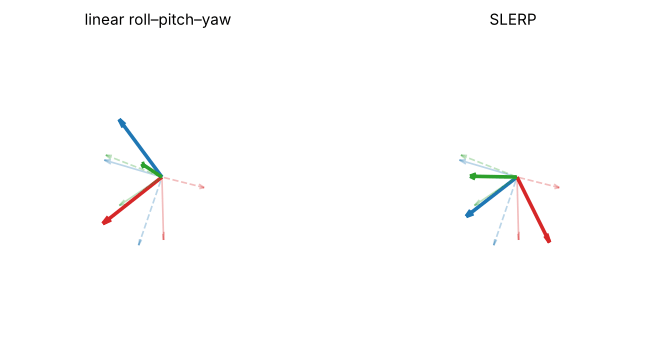

angle between the two interpolants at t = 0.50: 84.2 deg;   geodesic distance start-goal: 103.9 deg


In [14]:
PAIRS = {"near the pitch pole": (deg([-70.0, 85.0, -160.0]), deg([150.0, -10.0, 70.0])),
         "wrapped roll (UR5e-like)": (deg([-180.0, 0.0, 0.0]), deg([171.3, 18.1, 3.6])),
         "well-conditioned": (deg([10.0, 20.0, 30.0]), deg([40.0, -10.0, 100.0]))}

def explore_interp(pair="near the pitch pole", t=0.5):
    Ap, Bp = PAIRS[pair]
    Ra, Rb = rpy_to_rot(*Ap), rpy_to_rot(*Bp)
    Re, Rs_ = euler_lerp_R(Ap, Bp, t), slerp_R(Ra, Rb, t)
    fig = plt.figure(figsize=(8.4, 4.0))
    for j, (Rj, name) in enumerate(((Re, "linear roll–pitch–yaw"), (Rs_, "SLERP"))):
        ax = fig.add_subplot(1, 2, j + 1, projection="3d"); new_axes3d(ax, lim=1.1, title=name, ticks=False); ax.set_axis_off()
        draw_frame(ax, Ra, length=0.9, label_axes=False, lw=1.2, alpha=0.3); draw_frame(ax, Rb, length=0.9, label_axes=False, lw=1.2, alpha=0.3, ls="--")
        draw_frame(ax, Rj, length=0.95, label_axes=False, lw=2.6)
    plt.show()
    print(f"angle between the two interpolants at t = {t:.2f}: {np.degrees(axis_angle_from_R(Re.T @ Rs_)[1]):.1f} deg;   "
          f"geodesic distance start-goal: {np.degrees(axis_angle_from_R(Ra.T @ Rb)[1]):.1f} deg")

interact(explore_interp, pair=widgets.Dropdown(options=list(PAIRS), value="near the pitch pole", description="pair"),
         t=widgets.FloatSlider(0.5, min=0, max=1, step=0.05, description="t"));

## 9. Numerical drift and renormalisation

Robot controllers and inertial sensors update an orientation thousands of times per second by multiplying it with a small
rotation. In floating-point arithmetic each product incurs a relative rounding error of about $\varepsilon\approx10^{-7}$ (single
precision) or $10^{-16}$ (double precision). Two things drift:

* a rotation **matrix** slowly ceases to be orthonormal ($R^{\mathsf T}R\ne I$), and the error is not self-correcting;
* a **quaternion** slowly ceases to have unit length. The same sandwich product with a quaternion of length $\lambda\neq1$ would scale vectors by $\lambda^2$.

The repair differs sharply in cost. For a quaternion, **renormalise**: $q\leftarrow q/\lVert q\rVert$ — one square root and four divisions. For
a matrix one must project back onto $SO(3)$ — for example with the SVD, $R=U\,\mathrm{diag}(1,1,\det(UV^{\mathsf T}))V^{\mathsf T}$, as
`rgkit.transforms.orthonormalize` does — or apply Gram–Schmidt. (Renormalisation removes the *constraint violation*; the accumulated
error in the *rotation* itself, of order $\sqrt N\varepsilon$ after $N$ steps, remains but is harmless for realistic $N$.) The experiment composes $10^5$
rotations of $10^{-3}$ rad about the axis $(1,2,3)$ in **single precision** and tracks the constraint violations.

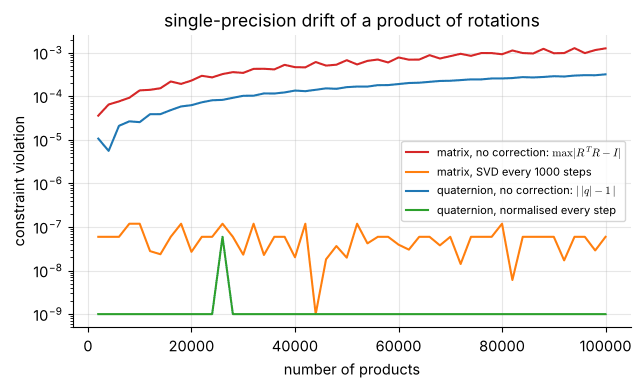

final constraint violations: matrix 1.3e-03  matrix + SVD 6.0e-08  quaternion 3.2e-04  quaternion normalised 0.0e+00
angle error of the accumulated rotation (deg): matrix 0.0026   quaternion 0.0062


In [15]:
axis_ = np.array([1.0, 2.0, 3.0]); dth_ = 1e-3; N = 100_000
Rstep = rot_axis_angle(axis_, dth_).astype(np.float32)
qstep = quat_from_axis_angle(axis_, dth_).astype(np.float32)

def qmul32(a, b):
    return np.array([a[0] * b[0] - a[1] * b[1] - a[2] * b[2] - a[3] * b[3], a[0] * b[1] + a[1] * b[0] + a[2] * b[3] - a[3] * b[2],
                     a[0] * b[2] - a[1] * b[3] + a[2] * b[0] + a[3] * b[1], a[0] * b[3] + a[1] * b[2] - a[2] * b[1] + a[3] * b[0]], dtype=np.float32)

R_raw = np.eye(3, dtype=np.float32); R_fix = np.eye(3, dtype=np.float32)
q_raw = np.array([1, 0, 0, 0], dtype=np.float32); q_fix = q_raw.copy()
rec = {"n": [], "R raw": [], "R fixed": [], "q raw": [], "q fixed": []}
for n in range(1, N + 1):
    R_raw = R_raw @ Rstep; R_fix = R_fix @ Rstep
    q_raw = qmul32(q_raw, qstep); q_fix = qmul32(q_fix, qstep); q_fix = q_fix / np.linalg.norm(q_fix)
    if n % 1000 == 0:
        R_fix = orthonormalize(R_fix).astype(np.float32)               # SVD every 1000 steps
    if n % 2000 == 0:
        rec["n"].append(n); rec["R raw"].append(abs(R_raw.T @ R_raw - np.eye(3)).max()); rec["R fixed"].append(abs(R_fix.T @ R_fix - np.eye(3)).max())
        rec["q raw"].append(abs(np.linalg.norm(q_raw) - 1)); rec["q fixed"].append(abs(np.linalg.norm(q_fix) - 1))

plt.figure(figsize=(7.2, 3.8))
plt.semilogy(rec["n"], rec["R raw"], label=r"matrix, no correction: $\max|R^TR-I|$", color="#d62728")
plt.semilogy(rec["n"], np.maximum(rec["R fixed"], 1e-9), label="matrix, SVD every 1000 steps", color="#ff7f0e")
plt.semilogy(rec["n"], rec["q raw"], label=r"quaternion, no correction: $|\,|q|-1\,|$", color="#1f77b4")
plt.semilogy(rec["n"], np.maximum(rec["q fixed"], 1e-9), label="quaternion, normalised every step", color="#2ca02c")
plt.xlabel("number of products"); plt.ylabel("constraint violation"); plt.legend(fontsize=8); plt.title("single-precision drift of a product of rotations"); plt.show()
exact = rot_axis_angle(axis_, N * dth_)
print("final constraint violations: matrix", f"{rec['R raw'][-1]:.1e}", " matrix + SVD", f"{rec['R fixed'][-1]:.1e}",
      " quaternion", f"{rec['q raw'][-1]:.1e}", " quaternion normalised", f"{rec['q fixed'][-1]:.1e}")
print("angle error of the accumulated rotation (deg): matrix", np.degrees(axis_angle_from_R(exact.T @ R_fix.astype(float))[1]).round(4),
      "  quaternion", np.degrees(axis_angle_from_R(exact.T @ R_from_quat(q_fix.astype(float)))[1]).round(4))

## 10. Quaternions in MuJoCo and a rotation vector for the UR5e

MuJoCo stores every orientation as a **unit quaternion, scalar first**: `data.xquat[i]` is the world orientation of body $i$ as
$(w,x,y,z)$, `model.body_quat[i]` the body's orientation relative to its parent, and the four orientation entries of a free joint in `qpos[3:7]`
follow the same order. The world orientation of a body is — exactly as in Section 2.2, but in quaternion form —

$$
q_{\text{world},i} = q_{\text{world},\,\text{parent}(i)}\otimes q_{\text{body},i}\otimes q_{\text{joint},i}(\vartheta_i),
\qquad q_{\text{joint}} = \Big(\cos\frac{\vartheta}{2},\ \hat a\,\sin\frac{\vartheta}{2}\Big),
$$

where $\hat a$ is the joint axis expressed in the body frame. The cell checks this chain for every link of the UR5e at a random
configuration, compares `xquat` with the quaternion obtained from `xmat` by our Shepperd function, and tests MuJoCo's own quaternion
utilities against ours. SciPy returns quaternions **scalar last**, so we reorder them explicitly.

In [16]:
from rgkit import mujoco_utils as mju, robots              # selects an OpenGL backend; import before mujoco
import mujoco
model, data = robots.load_robot("ur5e")
rng = np.random.default_rng(4)
data.qpos[:6] = rng.uniform(-np.pi, np.pi, 6); mujoco.mj_forward(model, data)

same_rot = lambda a, b: min(np.linalg.norm(a - b), np.linalg.norm(a + b)) < 1e-12        # q and -q are the same rotation
print("body                 parent               xquat = parent (x) body_quat (x) joint?   xquat from xmat?")
for i in range(1, model.nbody):
    parent = model.body_parentid[i]
    q_local = model.body_quat[i].copy()
    j = model.body_jntadr[i]
    if j >= 0 and model.body_jntnum[i] > 0:
        q_local = quat_mul(q_local, quat_from_axis_angle(model.jnt_axis[j], data.qpos[model.jnt_qposadr[j]]))
    q_chain = quat_mul(data.xquat[parent], q_local) if parent > 0 else q_local
    ok_chain = same_rot(q_chain, data.xquat[i])
    ok_mat = same_rot(quat_from_R(data.xmat[i].reshape(3, 3)), data.xquat[i])
    assert ok_chain and ok_mat
    print(f"{model.body(i).name:20s} {model.body(parent).name:20s} {ok_chain!s:38s}{ok_mat}")

# MuJoCo's own utilities versus ours
qa_, qb_ = quat_from_axis_angle([1, 2, 3], 0.7), quat_from_axis_angle([-1, 0.5, 2], -1.9)
out = np.zeros(4); mujoco.mju_mulQuat(out, qa_, qb_); print("\nmju_mulQuat == our quaternion product:", np.allclose(out, quat_mul(qa_, qb_)))
mat = np.zeros(9); mujoco.mju_quat2Mat(mat, qa_); print("mju_quat2Mat == our R(q):", np.allclose(mat.reshape(3, 3), quat_to_rot(qa_)))
qm = np.zeros(4); mujoco.mju_mat2Quat(qm, mat); print("mju_mat2Quat recovers q:", same_rot(qm, qa_))
v_out = np.zeros(3); mujoco.mju_rotVecQuat(v_out, [0.3, -1.0, 2.0], qa_); print("mju_rotVecQuat == sandwich product:", np.allclose(v_out, quat_rotate(qa_, [0.3, -1.0, 2.0])))
q_sp = Rot.from_matrix(quat_to_rot(qa_)).as_quat()                 # SciPy: (x, y, z, w)
print("SciPy as_quat is scalar LAST:", np.allclose(q_sp[[3, 0, 1, 2]], qa_) or np.allclose(-q_sp[[3, 0, 1, 2]], qa_))

# a free body whose orientation is set from our quaternion (qpos[3:7] = w, x, y, z)
xml = """<mujoco><worldbody><body name="b"><freejoint name="fj"/><geom type="box" size="0.1 0.05 0.02"/></body></worldbody></mujoco>"""
m2, d2 = mju.load(xml); mju.set_free_pose(m2, d2, "fj", [0.1, 0.2, 0.3], qa_)
print("free body: xmat equals R(q):", np.allclose(d2.body("b").xmat.reshape(3, 3), quat_to_rot(qa_)), "  xquat =", d2.body("b").xquat.round(4), " q =", qa_.round(4))

body                 parent               xquat = parent (x) body_quat (x) joint?   xquat from xmat?
base                 world                True                                  True
shoulder_link        base                 True                                  True
upper_arm_link       shoulder_link        True                                  True
forearm_link         upper_arm_link       True                                  True
wrist_1_link         forearm_link         True                                  True
wrist_2_link         wrist_1_link         True                                  True
wrist_3_link         wrist_2_link         True                                  True

mju_mulQuat == our quaternion product: True
mju_quat2Mat == our R(q): True
mju_mat2Quat recovers q: True
mju_rotVecQuat == sandwich product: True
SciPy as_quat is scalar LAST: True
free body: xmat equals R(q): True   xquat = [0.9394 0.0916 0.1833 0.2749]  q = [0.9394 0.0916 0.1833 0.2749]


**Rotation vectors in robot programs.** Industrial robot programs and controllers often specify orientations as a **rotation vector**
$(r_x, r_y, r_z) = \theta\hat k$ — the exponential coordinates of this section. Universal Robots controllers, for example, express the
pose of the tool centre point as a position and a rotation vector, whose *length is the angle in radians* and whose direction is the axis.
The reference frame and sign conventions are those of the manufacturer's manual and should always be checked. In the simulator we can produce
the same kind of number for the UR5e's tool frame: it is the rotation vector of the tool's world orientation as MuJoCo reports it (the
*simulator's* world frame, not a particular controller's base frame). At the home pose the tool points straight down, a rotation of exactly $\pi$ about a
horizontal axis — the case in which the sign of the vector is ambiguous (Section 3) and the number the robot displays can switch sign.

In [17]:
def tool_orientation(q_deg):
    data.qpos[:6] = np.radians(q_deg); mujoco.mj_forward(model, data)
    return data.site("attachment_site").xmat.reshape(3, 3).copy()

configs = {"home": [-90, -90, 90, -90, -90, 0], "A": [-60, -110, 100, -80, -70, 25], "B": [30, -70, 80, -100, -45, 60]}
rows = ["| configuration | rotation vector θk (rad) | angle θ (°) | quaternion (w, x, y, z) | exp(θk) reproduces R |", "|:--|:--|--:|:--|:--|"]
for name, q_deg in configs.items():
    R = tool_orientation(q_deg)
    k_, th_ = axis_angle_from_R(R); r_ = th_ * k_
    r_sp = Rot.from_matrix(R).as_rotvec()
    assert np.allclose(expm(skew(r_)), R) and (np.allclose(r_, r_sp, atol=1e-6) or np.isclose(th_, np.pi, atol=1e-6))
    rows.append(f"| {name} | ({r_[0]:+.3f}, {r_[1]:+.3f}, {r_[2]:+.3f}) | {np.degrees(th_):.1f} | {np.round(quat_from_R(R), 3).tolist()} | True |")
display(Markdown("\n".join(rows)))
print("at the home pose the tool is rotated by", np.degrees(axis_angle_from_R(tool_orientation(configs['home']))[1]).round(3), "deg about a horizontal axis")

| configuration | rotation vector θk (rad) | angle θ (°) | quaternion (w, x, y, z) | exp(θk) reproduces R |
|:--|:--|--:|:--|:--|
| home | (+3.142, -0.000, -0.000) | 180.0 | [0.0, 1.0, 0.0, -0.0] | True |
| A | (+2.942, +0.128, -0.461) | 170.8 | [0.08, 0.984, 0.043, -0.154] | True |
| B | (+2.041, +1.178, +0.000) | 135.0 | [0.383, 0.8, 0.462, -0.0] | True |

at the home pose the tool is rotated by 180.0 deg about a horizontal axis


## 11. Worked examples

**Example 2.5.1 — angle and axis of a product.** Find the equivalent angle–axis pair of $R=R_Z(90^\circ)R_Y(90^\circ)$.

*Solution.* $R_Y(90^\circ)=\begin{bmatrix}0&0&1\\0&1&0\\-1&0&0\end{bmatrix}$ and so $R=\begin{bmatrix}0&-1&0\\0&0&1\\-1&0&0\end{bmatrix}$ (rows: the first row of
$R_Z(90^\circ)$ times the columns of $R_Y(90^\circ)$, and so on). The trace is $0$, so $\cos\theta=-\tfrac12$ and $\theta=120^\circ$. The axis is
$\mathbf v/\sin\theta$ with $\mathbf v=\tfrac12(r_{32}-r_{23},\ r_{13}-r_{31},\ r_{21}-r_{12}) = \tfrac12(0-1,\ 0-(-1),\ 0-(-1))=(-\tfrac12,\tfrac12,\tfrac12)$,
$\sin120^\circ=\tfrac{\sqrt3}{2}$: $\hat k = \tfrac1{\sqrt3}(-1,1,1)$. Two quarter turns about perpendicular axes equal one third of a turn about a cube diagonal.

**Example 2.5.2 — Rodrigues.** Rotate $\mathbf p=(1,2,3)$ by $120^\circ$ about $\hat k=\tfrac1{\sqrt3}(1,1,1)$.

*Solution.* $\hat k\cdot\mathbf p=\tfrac{6}{\sqrt3}$, so $(1-\cos120^\circ)(\hat k\cdot\mathbf p)\hat k=\tfrac32\cdot\tfrac6{\sqrt3}\cdot\tfrac1{\sqrt3}(1,1,1)=(3,3,3)$;
$\cos120^\circ\,\mathbf p=(-0.5,-1,-1.5)$; $\hat k\times\mathbf p=\tfrac1{\sqrt3}(1,1,1)\times(1,2,3)=\tfrac1{\sqrt3}(1,-2,1)$ and $\sin120^\circ\,\hat k\times\mathbf p=\tfrac12(1,-2,1)=(0.5,-1,0.5)$.
Adding, $\mathbf p'=(3,\,1,\,2)$: the rotation cyclically permutes the axes, $x\to y\to z\to x$, and so permutes the coordinates.

**Example 2.5.3 — a quaternion product by hand.** Let $q_1=(2,\,1,\,-1,\,0)$ and $q_2=(1,\,3,\,2,\,-2)$. Find $q_1\otimes q_2$ and $q_2\otimes q_1$.

*Solution.* Scalar part: $s_1s_2-\mathbf v_1\cdot\mathbf v_2 = 2\cdot1-(1\cdot3+(-1)\cdot2+0\cdot(-2))=2-1=1$ (the same for both orders).
Vector part: $s_1\mathbf v_2+s_2\mathbf v_1+\mathbf v_1\times\mathbf v_2 = 2(3,2,-2)+1(1,-1,0)+(1,-1,0)\times(3,2,-2)$ with
$(1,-1,0)\times(3,2,-2)=(2,\,2,\,5)$, giving $(6,4,-4)+(1,-1,0)+(2,2,5)=(9,5,1)$. So $q_1\otimes q_2=(1,\,9,\,5,\,1)$, while
$q_2\otimes q_1=(1,\,5,\,1,\,-9)$ (the cross product changes sign: $(6,4,-4)+(1,-1,0)-(2,2,5)=(5,1,-9)$). Check: $\lVert q_1\rVert\lVert q_2\rVert=\sqrt6\sqrt{18}=10.392=\lVert q_1\otimes q_2\rVert=\sqrt{108}$.

**Example 2.5.4 — roll–pitch–yaw to quaternion.** Roll $25^\circ$, pitch $-40^\circ$, yaw $110^\circ$. Find $q$ and recover the angles.

*Solution.* With half angles $12.5^\circ,\,-20^\circ,\,55^\circ$, the product $q_Z(110^\circ)\otimes q_Y(-40^\circ)\otimes q_X(25^\circ)$ is
$q=(0.4656,\ 0.3902,\ -0.0249,\ 0.7940)$. The inverse formulas give roll $=\operatorname{atan2}(2(wx+yz),\,1-2(x^2+y^2))=25^\circ$,
pitch $=\arcsin(2(wy-zx))=-40^\circ$, yaw $=\operatorname{atan2}(2(wz+xy),\,1-2(y^2+z^2))=110^\circ$.

**Example 2.5.5 — a quaternion from a matrix.** Find the unit quaternion and the angle–axis pair of $R=R_Z(30^\circ)R_Y(60^\circ)R_X(-45^\circ)$.

*Solution.* Numerically $R=\begin{bmatrix}0.4330&-0.8839&0.1768\\0.2500&0.3062&0.9186\\-0.8660&-0.3536&0.3536\end{bmatrix}$. The squares
$4w^2=1+\operatorname{tr}R=2.0928$, $4x^2=1+r_{11}-r_{22}-r_{33}=0.7733$, so $w$ is largest: $w=0.7233$,
$x=(r_{32}-r_{23})/4w=-0.4397$, $y=(r_{13}-r_{31})/4w=0.3604$, $z=(r_{21}-r_{12})/4w=0.3919$. The angle is $2\arccos w=87.34^\circ$ and the axis
$(−0.6367,\,0.5220,\,0.5676)$.

**Example 2.5.6 — SLERP.** Find the orientation half way between the identity and a rotation of $100^\circ$ about $(1,1,0)/\sqrt2$.

*Solution.* $q_0=(1,0,0,0)$, $q_1=(\cos50^\circ,\ \sin50^\circ(1,1,0)/\sqrt2)=(0.6428,\,0.5417,\,0.5417,\,0)$, $\cos\Omega=0.6428$, $\Omega=50^\circ$.
At $t=\tfrac12$ both weights equal $\sin25^\circ/\sin50^\circ=0.5517$, so $q=0.5517(q_0+q_1)=(0.9063,\,0.2988,\,0.2988,\,0)$, which is a rotation of $2\cos^{-1}(0.9063)=50^\circ$ about the same axis, exactly half-way.

The cell verifies all six examples.

In [18]:
# 2.5.1
R = rotz(deg(90)) @ roty(deg(90)); k_, th_ = axis_angle_from_R(R)
assert np.allclose(R, [[0, -1, 0], [0, 0, 1], [-1, 0, 0]]) and np.isclose(np.degrees(th_), 120) and np.allclose(k_, np.array([-1, 1, 1]) / np.sqrt(3))
print("Ex 2.5.1: theta =", np.degrees(th_).round(3), "deg, k*sqrt(3) =", (k_ * np.sqrt(3)).round(3))
# 2.5.2
p2 = rot_axis_angle([1, 1, 1], deg(120)) @ [1, 2, 3]; assert np.allclose(p2, [3, 1, 2]); print("Ex 2.5.2: p' =", p2.round(6))
# 2.5.3
q1_, q2_ = np.array([2.0, 1, -1, 0]), np.array([1.0, 3, 2, -2])
assert np.allclose(quat_mul(q1_, q2_), [1, 9, 5, 1]) and np.allclose(quat_mul(q2_, q1_), [1, 5, 1, -9])
assert np.isclose(np.linalg.norm(q1_) * np.linalg.norm(q2_), np.linalg.norm(quat_mul(q1_, q2_)))
print("Ex 2.5.3: q1 q2 =", quat_mul(q1_, q2_), " q2 q1 =", quat_mul(q2_, q1_), " norms", np.linalg.norm(q1_) * np.linalg.norm(q2_))
# 2.5.4
q = quat_from_rpy(deg(25), deg(-40), deg(110)); assert np.allclose(q, [0.4656, 0.3902, -0.0249, 0.7940], atol=5e-5)
assert np.allclose(np.degrees(rpy_from_quat(q)), [25, -40, 110]); print("Ex 2.5.4: q =", q.round(4), " angles =", np.degrees(rpy_from_quat(q)).round(3))
# 2.5.5
R = rotz(deg(30)) @ roty(deg(60)) @ rotx(deg(-45)); q = quat_from_R(R); k_, th_ = axis_angle_from_R(R)
assert np.allclose(R[0], [0.4330, -0.8839, 0.1768], atol=5e-5) and np.allclose(R[2], [-0.8660, -0.3536, 0.3536], atol=5e-5)
assert np.allclose(q, [0.7233, -0.4397, 0.3604, 0.3919], atol=5e-5) and np.isclose(np.degrees(th_), 87.34, atol=0.01) and np.allclose(k_, [-0.6367, 0.5220, 0.5676], atol=5e-5)
assert np.isclose(1 + np.trace(R), 2.0928, atol=5e-5) and np.isclose(1 + R[0, 0] - R[1, 1] - R[2, 2], 0.7733, atol=5e-5)
print("Ex 2.5.5: q =", q.round(4), " theta =", np.degrees(th_).round(2), " k =", k_.round(4))
# 2.5.6
q0 = np.array([1.0, 0, 0, 0]); q1 = quat_from_axis_angle([1, 1, 0], deg(100)); qh = slerp(q0, q1, 0.5)
assert np.allclose(q1, [0.6428, 0.5417, 0.5417, 0], atol=5e-5) and np.isclose(np.sin(deg(25)) / np.sin(deg(50)), 0.5517, atol=5e-5)
assert np.allclose(qh, [0.9063, 0.2988, 0.2988, 0], atol=5e-5) and np.allclose(qh, quat_from_axis_angle([1, 1, 0], deg(50)))
print("Ex 2.5.6: slerp(0.5) =", qh.round(4))

Ex 2.5.1: theta = 120.0 deg, k*sqrt(3) = [-1.  1.  1.]
Ex 2.5.2: p' = [3. 1. 2.]
Ex 2.5.3: q1 q2 = [1. 9. 5. 1.]  q2 q1 = [ 1.  5.  1. -9.]  norms 10.392304845413262
Ex 2.5.4: q = [ 0.4656  0.3902 -0.0249  0.794 ]  angles = [ 25. -40. 110.]
Ex 2.5.5: q = [ 0.7233 -0.4397  0.3604  0.3919]  theta = 87.34  k = [-0.6367  0.522   0.5676]
Ex 2.5.6: slerp(0.5) = [0.9063 0.2988 0.2988 0.    ]


## 12. Summary

| Representation | Numbers | Constraints | Singular or ambiguous | Best for |
|:--|:--:|:--:|:--|:--|
| Rotation matrix | 9 | 6 | none (unique) | computation, chaining frames, rotating many vectors |
| Three angles (fixed / Euler) | 3 | 0 | gimbal lock; two solutions in general | human input, teach pendants, display |
| Angle–axis $(\hat k,\theta)$ | 4 | 1 | axis undefined at $\theta=0$; sign ambiguity at $\theta=\pi$ | intuition, orientation *error*, conversions |
| Rotation vector $\theta\hat k$ | 3 | 0 | ball of radius $\pi$ with antipodes identified; log undefined sign at $\pi$ | small corrections, controllers that read $(r_x,r_y,r_z)$, optimisation |
| Unit quaternion | 4 | 1 | none; $q$ and $-q$ are the same rotation | storage, composition, interpolation, sensor fusion |

| Result | Formula |
|:--|:--|
| Rodrigues | $R=I+\sin\theta\,[\hat k]_\times+(1-\cos\theta)[\hat k]_\times^2=e^{[\hat k]_\times\theta}$ |
| Inverse | $\theta=\operatorname{atan2}(\lVert\mathbf v\rVert,\tfrac12(\operatorname{tr}R-1))$, $\ \hat k=\mathbf v/\lVert\mathbf v\rVert$, $\ \mathbf v=\tfrac12\operatorname{unskew}(R-R^{\mathsf T})$ |
| Quaternion product | $q_1\otimes q_2=(s_1s_2-\mathbf v_1\cdot\mathbf v_2,\ s_1\mathbf v_2+s_2\mathbf v_1+\mathbf v_1\times\mathbf v_2)$ |
| Rotation quaternion | $q=(\cos\frac\theta2,\ \hat k\sin\frac\theta2)$; $\ (0,\mathbf p')=q\otimes(0,\mathbf p)\otimes q^{*}$; $\ R_1R_2\leftrightarrow q_1\otimes q_2$ |
| SLERP | $q(t)=\frac{\sin((1-t)\Omega)}{\sin\Omega}q_0+\frac{\sin(t\Omega)}{\sin\Omega}q_1$, $\cos\Omega=q_0\cdot q_1\ge0$ |
| Drift repair | quaternion: $q\leftarrow q/\lVert q\rVert$; matrix: SVD projection onto $SO(3)$ |
| MuJoCo | `xquat` is scalar first, $(w,x,y,z)$; SciPy and ROS are scalar last |

### Common mistakes

* **Scalar position.** Mixing $(w,x,y,z)$ and $(x,y,z,w)$ is the most frequent quaternion bug; the numbers look plausible and are wrong.
* **Forgetting the half angle**: the quaternion of a $90^\circ$ rotation has $\cos45^\circ$, not $\cos90^\circ$.
* **Treating $q$ and $-q$ as different** rotations when comparing, averaging or interpolating (flip one if $q_0\cdot q_1<0$).
* **Multiplying in the wrong order**: $q_1\otimes q_2$ is *not* $q_2\otimes q_1$.
* Using $\arccos$ for the angle (inaccurate near $0$ and $\pi$) or $1/(2\sin\theta)$ for the axis at $\theta=\pi$.
* Interpolating **Euler angles** or **matrix entries** instead of using SLERP or the exponential map.
* Not renormalising after many incremental updates.

## Exercises

**2.5.1** Show that the rotation $R_X(90^\circ)R_Z(90^\circ)$ has angle $120^\circ$ and find its axis. Is it the same axis as in Example 2.5.1?

<details><summary>Answer</summary>

$R=\begin{bmatrix}0&-1&0\\0&0&-1\\1&0&0\end{bmatrix}$, trace $0$, so $\theta=120^\circ$; $\mathbf v=\tfrac12(r_{32}-r_{23},r_{13}-r_{31},r_{21}-r_{12})=\tfrac12(1,-1,1)$ and the axis is $\tfrac1{\sqrt3}(1,-1,1)$ — a different cube diagonal, because the two matrices are different rotations (in a different order).
</details>

**2.5.2** Derive the formula $\operatorname{tr}R=1+2\cos\theta$ from Rodrigues' formula, and the formula $R-R^{\mathsf T}=2\sin\theta[\hat k]_\times$.

<details><summary>Answer</summary>

$\operatorname{tr}I=3$, $\operatorname{tr}[\hat k]_\times=0$ and $\operatorname{tr}[\hat k]_\times^2=\operatorname{tr}(\hat k\hat k^{\mathsf T}-I)=1-3=-2$, so $\operatorname{tr}R=3-2(1-\cos\theta)=1+2\cos\theta$. $I$ and $[\hat k]_\times^2$ are symmetric and $[\hat k]_\times$ is skew, so $R-R^{\mathsf T}=2\sin\theta[\hat k]_\times$.
</details>

**2.5.3** Compute $q\otimes(0,\mathbf p)\otimes q^{*}$ for $q=(\cos45^\circ,\,0,\,0,\,\sin45^\circ)$ and $\mathbf p=(1,0,0)$ and interpret.

<details><summary>Answer</summary>

$q=(0.7071,0,0,0.7071)$ is a $90^\circ$ rotation about $Z$; the result is $(0,\ 0,\ 1,\ 0)$, i.e. $\mathbf p'=(0,1,0)$ — the same as $R_Z(90^\circ)(1,0,0)^{\mathsf T}$.
</details>

**2.5.4** Show that SLERP between $q_0$ and $q_1$ and the spherical interpolation between $q_0$ and $-q_1$ describe the *same* orientations at $t=0$ and $t=1$, but pass through different intermediate orientations. Which one is shorter?

<details><summary>Answer</summary>

$q_1$ and $-q_1$ are the same rotation, so the end orientations agree. The arcs from $q_0$ to $q_1$ and from $q_0$ to $-q_1$ are the two great-circle arcs between $q_0$ and the antipodal pair; their lengths are $\Omega$ and $\pi-\Omega$ with $\cos\Omega=q_0\cdot q_1$. The shorter arc has $q_0\cdot q_1\ge0$, which is the one SLERP selects (the corresponding rotation angles are $2\Omega$ and $2\pi-2\Omega$).
</details>

**2.5.5** (*Programming*) Implement the quaternion average of $n$ rotations by summing the quaternions (after flipping signs to the hemisphere of the first) and normalising. Test it on rotations about $Z$ by $-10^\circ$, $0^\circ$, $10^\circ$ and explain why the naive average of the *matrices* is not a rotation.

<details><summary>Answer</summary>

The normalised sum of $(\cos5^\circ,0,0,-\sin5^\circ)$, $(1,0,0,0)$, $(\cos5^\circ,0,0,\sin5^\circ)$ is $(1,0,0,0)$, the identity; the verification cell shows the code. The average of rotation matrices is not orthonormal in general (rows shrink in length), so it must be projected back onto $SO(3)$.
</details>

**2.5.6** (*Numerical*) The rotation vector of a tool is $\boldsymbol r=(0,\ \pi/2,\ 0)$ rad. Find $R$, $q$, and the pitch of the tool in roll–pitch–yaw.

<details><summary>Answer</summary>

$\theta=\pi/2$, $\hat k=\hat Y$: $R=R_Y(90^\circ)=\begin{bmatrix}0&0&1\\0&1&0\\-1&0&0\end{bmatrix}$, $q=(0.7071,0,0.7071,0)$, and the pitch is exactly $90^\circ$ — the gimbal-lock configuration of Section 2.4, where the quaternion and the rotation vector are perfectly well behaved.
</details>

**2.5.7** (*MuJoCo*) For the UR5e at joint angles $q=(0.3,-1.1,1.4,-0.5,0.8,0.2)$ rad, read `data.xquat` of `wrist_3_link`. Verify that it equals the product of the body quaternions and joint quaternions along the chain from `base`.

<details><summary>Answer</summary>

Exactly the check of Section 10; the verification cell below repeats it for this configuration and confirms that the product matches up to the overall sign of the quaternion.
</details>

### Checking the answers by computation

In [19]:
# 2.5.1
R = rotx(deg(90)) @ rotz(deg(90)); k_, th_ = axis_angle_from_R(R)
assert np.allclose(R, [[0, -1, 0], [0, 0, -1], [1, 0, 0]]) and np.isclose(np.degrees(th_), 120) and np.allclose(k_, np.array([1, -1, 1]) / np.sqrt(3))
# 2.5.2
K_ = skew([0.3, -0.5, 0.8] / np.linalg.norm([0.3, -0.5, 0.8])); th_ = 0.9
R_ = np.eye(3) + np.sin(th_) * K_ + (1 - np.cos(th_)) * K_ @ K_
assert np.isclose(np.trace(R_), 1 + 2 * np.cos(th_)) and np.allclose(R_ - R_.T, 2 * np.sin(th_) * K_) and np.isclose(np.trace(K_ @ K_), -2)
# 2.5.3
qq = quat_from_axis_angle([0, 0, 1], deg(90)); assert np.allclose(qq, [0.7071, 0, 0, 0.7071], atol=5e-5)
assert np.allclose(quat_rotate(qq, [1, 0, 0]), [0, 1, 0])
# 2.5.4: the two arcs have rotation angles 2*Omega and 2*pi - 2*Omega
q0, q1 = quat_from_axis_angle([0, 0, 1], deg(50)), quat_from_axis_angle([1, 1, 0], deg(160))
Om = np.arccos(q0 @ q1); print("2.5.4  Omega =", np.degrees(Om).round(2), "deg; arc lengths:", np.degrees(Om).round(2), np.degrees(np.pi - Om).round(2))
assert np.allclose(quat_to_rot(q1), quat_to_rot(-q1))
# 2.5.5: quaternion average
qs = [quat_from_axis_angle([0, 0, 1], deg(a)) for a in (-10, 0, 10)]
qsum = sum(q if q @ qs[0] >= 0 else -q for q in qs); qavg = qsum / np.linalg.norm(qsum)
Rmean = np.mean([rotz(deg(a)) for a in (-10, 0, 10)], axis=0)
print("2.5.5  average quaternion:", qavg.round(6), " mean of matrices is a rotation?", is_rotation(Rmean), "  |first column| =", np.linalg.norm(Rmean[:, 0]).round(4))
assert np.allclose(qavg, [1, 0, 0, 0]) and not is_rotation(Rmean)
# 2.5.6
r_ = np.array([0, np.pi / 2, 0]); k_, th_ = r_ / np.linalg.norm(r_), np.linalg.norm(r_)
R = rot_axis_angle(k_, th_); assert np.allclose(R, roty(deg(90))) and np.allclose(quat_from_axis_angle(k_, th_), [0.7071, 0, 0.7071, 0], atol=5e-5)
assert np.isclose(np.degrees(rot_to_rpy(R)[1]), 90)
# 2.5.7
qj = np.array([0.3, -1.1, 1.4, -0.5, 0.8, 0.2]); data.qpos[:6] = qj; mujoco.mj_forward(model, data)
q_acc = np.array([1.0, 0, 0, 0])
for i in range(1, model.nbody):
    j = model.body_jntadr[i]                                           # the base link has no joint
    q_loc = model.body_quat[i] if j < 0 else quat_mul(model.body_quat[i], quat_from_axis_angle(model.jnt_axis[j], qj[model.jnt_qposadr[j]]))
    q_acc = quat_mul(q_acc, q_loc)
print("2.5.7  chain product:", q_acc.round(4), " xquat of wrist_3_link:", data.body("wrist_3_link").xquat.round(4))
assert same_rot(q_acc, data.body("wrist_3_link").xquat)

2.5.4  Omega = 80.95 deg; arc lengths: 80.95 99.05
2.5.5  average quaternion: [1. 0. 0. 0.]  mean of matrices is a rotation? False   |first column| = 0.9899
2.5.7  chain product: [ 0.0765  0.9678 -0.2397  0.0116]  xquat of wrist_3_link: [ 0.0765  0.9678 -0.2397  0.0116]


## Further reading and lectures

* Craig §2.8; Lynch & Park §3.2.3 and Appendix B; Siciliano et al. §2.5–2.6; Corke, *RVC*, Ch. 2; Spong et al., Ch. 2.
* Video: [Prof. G. C. Nandi, Lecture 10 — Rotation matrix when the body is rotated about a given axis](https://www.youtube.com/watch?v=eItbJ-WYzAE); [Prof. G. C. Nandi, Lecture 13 — Orientation description using quaternion: why is it more useful?](https://www.youtube.com/watch?v=UxC8Ho5e6_Y); [Prof. G. C. Nandi, Lecture 14 — Use of quaternion for rotation](https://www.youtube.com/watch?v=uGzl-TW68Pw); [Modern Robotics 3.2.3 Exponential coordinates of rotation (part 1)](https://www.youtube.com/watch?v=v_KBHaG0mas); [Modern Robotics 3.2.3 Exponential coordinates of rotation (part 2)](https://www.youtube.com/watch?v=WHn9xJl43nY); [ThatsEngineering — Fixed and Euler angle representation](https://www.youtube.com/watch?v=uG0P9RX65Ek).
* MuJoCo documentation: [quaternions and orientation specifications in MJCF](https://mujoco.readthedocs.io/en/stable/modeling.html#frame-orientations);
  SciPy: [`scipy.spatial.transform.Rotation`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.transform.Rotation.html).

---

[← 2.4 Fixed Angles and Euler Angles](2.4-fixed-angles-and-euler-angles.ipynb) &nbsp;·&nbsp; [Chapter contents](README.md)